# Phase D — RMTB Uncertainty Quantification (Steps 1-5)

One notebook, Steps 1-5 of `docs/PhaseD_implementation_roadmap.md` in
sequence (RMTB only, 2-D only — RMTC and $N>2$ are out of scope here, per the
roadmap). Each step reuses the model fit once at the top, rather than
refitting it per step, since nothing after Step 1 changes the training data.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from smt.surrogate_models import RMTB

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})


## Step 1 — Fit RMTB on a small, known 2-D case

Scope, deliberately narrow: **produce a trained `RMTB` model to extract from
in later steps — no variance computation here.** This section only confirms
the fit itself is sound (mean RMSE against the known true function, basic
diagnostics) and that the attributes later steps need are present.


Same synthetic target and noise level used throughout this project's 2-D
notebooks (`y = sin(3*x1)*cos(3*x2) + 0.05*N(0,1)`), on a regular `8x8` grid --
the "sparse grid" case from `03_rmts_vs_tensor_product_splines.ipynb`, chosen
here for the same reason: small enough to inspect by hand, large enough to be
a genuine (not degenerate) 2-D fitting problem.

In [2]:
def true_f(X):
    return np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1])

rng = np.random.default_rng(1)
n_side = 8
g = np.linspace(0, 1, n_side)
GX, GY = np.meshgrid(g, g, indexing="ij")
X = np.column_stack([GX.ravel(), GY.ravel()])
sigma2_true = 0.05 ** 2
y = true_f(X) + np.sqrt(sigma2_true) * rng.standard_normal(len(X))

print(f"n={len(X)} training points, true sigma2={sigma2_true:.4e}")


n=64 training points, true sigma2=2.5000e-03


Settings established and relied upon throughout this project (Research Plan
Phase C1/C2): `order=4` (cubic), `approx_order=2` (the Gaussian/L2 case,
required for the variance work to come -- `approx_order=4`, SMT's own
default, is a MAP estimator for a different, non-Gaussian objective and is not
valid for what Phase D needs), `solver="dense-lu"` (avoids the Krylov
non-convergence issue found earlier in this project). `num_ctrl_pts=20` and
`energy_weight=1e-2` reuse the same recipe already established in
`02_2d_splines_vs_kriging.ipynb`/`03_rmts_vs_tensor_product_splines.ipynb` --
not re-tuned here, since tuning is not this step's purpose.

In [3]:
def fit_rmtb(X, y, num_ctrl_pts=20, energy_weight=1e-2):
    m = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2,
              num_ctrl_pts=num_ctrl_pts, energy_weight=energy_weight,
              regularization_weight=1e-14, solver="dense-lu", print_global=False)
    m.set_training_values(X, y)
    m.train()
    return m


model = fit_rmtb(X, y)
print("trained.")


trained.


Mean-only check (matching the metric style used throughout this project):
RMSE against the *true* function (not the noisy data) on a dense grid, plus a
visual comparison. No variance, no uncertainty band -- those start in
Step 4.

In [4]:
gq = np.linspace(0, 1, 61)
GXq, GYq = np.meshgrid(gq, gq, indexing="ij")
Xq_dense = np.column_stack([GXq.ravel(), GYq.ravel()])
yq_true = true_f(Xq_dense)
yq_pred = model.predict_values(Xq_dense).ravel()

rmse = np.sqrt(np.mean((yq_pred - yq_true) ** 2))
max_err = np.max(np.abs(yq_pred - yq_true))
print(f"RMSE vs. true f (dense 61x61 grid): {rmse:.4e}")
print(f"max|error| vs. true f:              {max_err:.4e}   (true f range: {np.ptp(yq_true):.3f})")


RMSE vs. true f (dense 61x61 grid): 3.4074e-02
max|error| vs. true f:              7.9757e-02   (true f range: 1.990)


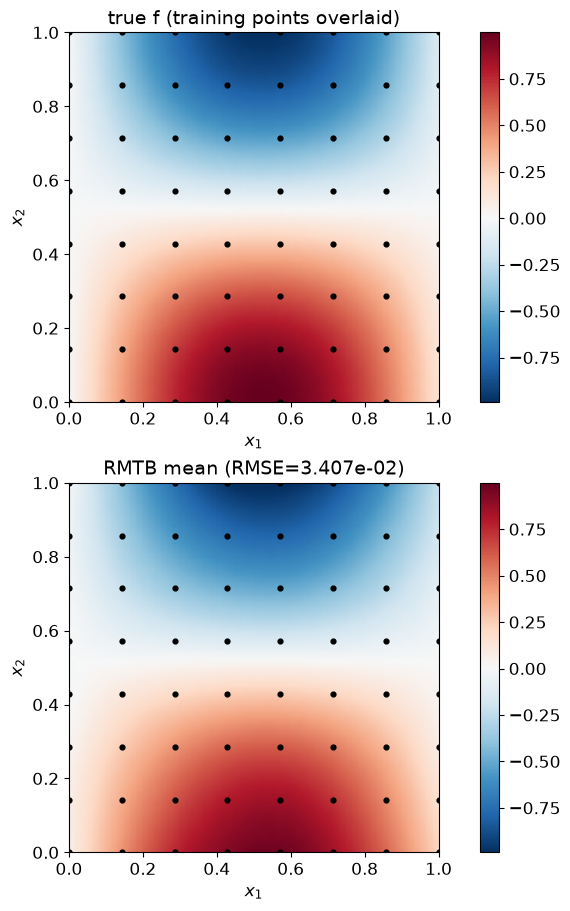

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(7, 9), constrained_layout=True)
vmin, vmax = yq_true.min(), yq_true.max()

pcm = axs[0].pcolormesh(GXq, GYq, yq_true.reshape(61, 61), shading="gouraud", cmap="RdBu_r",
                         vmin=vmin, vmax=vmax)
axs[0].scatter(X[:, 0], X[:, 1], c="k", s=12)
axs[0].set_title("true f (training points overlaid)")
fig.colorbar(pcm, ax=axs[0])

pcm = axs[1].pcolormesh(GXq, GYq, yq_pred.reshape(61, 61), shading="gouraud", cmap="RdBu_r",
                         vmin=vmin, vmax=vmax)
axs[1].scatter(X[:, 0], X[:, 1], c="k", s=12)
axs[1].set_title(f"RMTB mean (RMSE={rmse:.3e})")
fig.colorbar(pcm, ax=axs[1])

for ax in axs:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
plt.show()


Existence check only -- *using* these attributes correctly (confirming
`model.mtx == full_hess + Phi^T Phi`, deriving the dual route) is Step 2's
job.

In [6]:
for attr in ["full_hess", "full_jac_dict", "mtx", "sol"]:
    present = hasattr(model, attr)
    val = getattr(model, attr, None)
    shape = getattr(val, "shape", None)
    print(f"  model.{attr:16s} present={present!s:5s} shape={shape}")


  model.full_hess        present=True  shape=(400, 400)
  model.full_jac_dict    present=True  shape=None
  model.mtx              present=True  shape=(400, 400)
  model.sol              present=True  shape=(400, 1)


**Step 1 done.** Trained `RMTB` model, mean fit confirmed reasonable against
the known true function, every attribute Step 2 needs confirmed present.


## Step 2 — Extract $\Phi$, $H$; pin down both routes precisely

Still no variance numbers on real query points -- that is Step 4. This
section's job is narrower: establish *which* linear-algebra route is safe to
use, and confirm that before relying on it. Reuses the `model`, `X`, `y`
fit in Step 1 directly.

### Step 2a — confirm the weight-space system precisely, not on faith

Two facts the whole weight-space route depends on, verified here as this
notebook's own standing check (not inherited on faith): `model.mtx ==
full_hess + Phi^T Phi` exactly, and `model.sol` really is `mtx^-1 @ (Phi^T y)`
-- i.e. `model.sol` solves the textbook normal equations built from SMT's own
exposed matrices, not something subtly different.

In [7]:
H = model.full_hess.toarray()
Phi, PhiT, _c = model.full_jac_dict[0]
Phi = Phi.toarray()
mtx = model.mtx.toarray()
rhs = Phi.T @ y

print("max|mtx - (H + Phi^T Phi)| =", np.max(np.abs(mtx - (H + Phi.T @ Phi))))

w_solve = np.linalg.solve(mtx, rhs)
print("max|w_solve - model.sol|   =", np.max(np.abs(w_solve - model.sol.ravel())))


max|mtx - (H + Phi^T Phi)| = 1.3877787807814457e-17
max|w_solve - model.sol|   = 1.6395773627664312e-12


**Confirmed, both at solver precision.** The weight-space system this whole
route depends on is exactly what Research Plan Section 2.5/`csaps_grid_uq.py`'s
pattern would predict: `mtx = H + Phi^T Phi`, `sol = mtx^-1 (Phi^T y)`. Gemini's
suggested formula,

$$\mathrm{Var}(\hat y(x^*)) = \sigma^2 f(x^*)^\top \, \mathrm{mtx}^{-1} \, f(x^*)
= \sigma^2 \lVert L^{-1}f(x^*)^\top\rVert_2^2 \quad (\mathrm{mtx}=LL^\top),$$

is this project's own `Cov=sigma^2*A` tool (Research Plan Section 2.7) applied
with `A = mtx^-1` -- correct, *provided* `mtx` itself is safe to invert. That is
checked next, not assumed.

### Step 2b — a genuine finding, not anticipated by the roadmap as written: `H`
(`full_hess`) alone is itself essentially singular

Before trusting any "dual" construction built from `H^-1` (a Woodbury-style
rearrangement of `mtx^-1`, the natural-looking way to get an `n`-sized system
instead of an `m`-sized one), check whether `H^-1` is even a sound object to
compute.

In [8]:
eigH = np.linalg.eigvalsh(0.5 * (H + H.T))
print(f"H eigenvalue range: [{eigH.min():.3e}, {eigH.max():.3e}]")
print(f"cond(H) = {eigH.max()/eigH.min():.3e}")
print(f"eigenvalues below 1e-8: {np.sum(eigH < 1e-8)}  (smallest 6: {np.round(eigH[:6], 20)})")


H eigenvalue range: [8.832e-15, 1.194e+01]
cond(H) = 1.352e+15
eigenvalues below 1e-8: 4  (smallest 6: [8.83237000e-15 9.14986000e-15 9.67800000e-15 1.05975400e-14
 4.50250172e-04 4.56285182e-04])


**`cond(H) ~ 10^15` -- at float64's precision limit.** A handful of
eigenvalues sit at the `regularization_weight` floor (`beta=1e-14`) -- the
control-point directions `H`'s bending-energy term does not penalize at all
(the polynomial-trend null space, Research Plan Section 2.4/2.5), held in
place only by that thin ridge. **This rules out a naive Woodbury dual built by
inverting `H` directly** -- `H^-1` would be numerically meaningless in those
directions, the same failure mode Theorem 2a/2b's bordered system (Section 2.3)
exists specifically to avoid for the continuum case, via a Lagrange-multiplier
block rather than a literal inverse.

**Consequence for this roadmap, stated plainly:** building the *proper*
analog of the bordered system for RMTB's finite basis -- the version of the
"dual route" that would actually be safe to use whenever `mtx` itself is
unsafe -- needs its own careful derivation, mirroring how the trend null space
is already handled for the continuum Duchon kernel. That derivation is **not**
attempted in this notebook; it is deferred, named explicitly, rather than
shipped half-checked. What *is* checked here, and already cited in the
Research Plan as a validated fix for exactly this situation, is a safer
numerical method applied to the *same* `mtx` system: `np.linalg.lstsq`
(SVD-regularized), which does not require inverting `H` at all.

### Step 3 — is `mtx` itself safe for *this* model? Check before computing
anything else

`H` alone being near-singular does not necessarily mean `mtx = H + Phi^T Phi`
is -- the data term can fill in exactly the directions `H` leaves weak,
*if* there is enough data near enough to those control points (the same
mechanism already characterized in `RMTS_variance_potential_issues.md`).
Checked directly, not assumed, using the Research Plan Phase F3 safety-factor
reading (`trustworthy digits ~= 16 - log10(cond)`).

In [9]:
eig_mtx = np.linalg.eigvalsh(0.5 * (mtx + mtx.T))
cond_mtx = eig_mtx.max() / eig_mtx.min()
digits = 16 - np.log10(cond_mtx)
print(f"cond(mtx) = {cond_mtx:.3e}   (~{digits:.1f} trustworthy digits remaining)")

w_lstsq, *_ = np.linalg.lstsq(mtx, rhs, rcond=None)
gap = np.max(np.abs(w_solve - w_lstsq))
print(f"max|w_solve - w_lstsq| = {gap:.3e}   (predicted ~cond*eps = {cond_mtx*2.2e-16:.3e})")


cond(mtx) = 2.514e+04   (~11.6 trustworthy digits remaining)
max|w_solve - w_lstsq| = 2.352e-11   (predicted ~cond*eps = 5.532e-12)


**Safe for this model, and the forward-error bound is quantitatively
confirmed, not just qualitatively plausible**: `cond(mtx)~2.5e4` (~12
trustworthy digits), far under the `1e8` "suspect" line (Q17), and the two
independent routes (plain solve, SVD-regularized `lstsq`) agree to
`~2.4e-11` -- matching the predicted `cond*machine_epsilon` bound almost
exactly. **For this specific, well-resolved `8x8`-grid case, Gemini's
Cholesky-based formula is safe to trust directly.** The question still owed an
answer is *where that stops being true* -- checked next, reusing this
project's own established resolution-sweep pattern
(`03_rmts_vs_tensor_product_splines.ipynb`), not a fresh guess.

In [10]:
print(f"{'num_ctrl_pts':>13} {'m':>6} {'cond(mtx)':>11} {'digits':>8} {'solve-lstsq gap':>16}")
for ncp in [20, 40, 60, 80]:
    m_ = fit_rmtb(X, y, num_ctrl_pts=ncp)
    mtx_ = m_.mtx.toarray()
    Phi_, PhiT_, _c = m_.full_jac_dict[0]
    rhs_ = np.asarray(PhiT_ @ y.reshape(-1, 1)).ravel()
    eig_ = np.linalg.eigvalsh(0.5 * (mtx_ + mtx_.T))
    cond_ = eig_.max() / eig_.min()
    w1 = np.linalg.solve(mtx_, rhs_)
    w2, *_ = np.linalg.lstsq(mtx_, rhs_, rcond=None)
    gap_ = np.max(np.abs(w1 - w2))
    print(f"{ncp:13d} {ncp**2:6d} {cond_:11.2e} {16-np.log10(cond_):8.2f} {gap_:16.2e}")


 num_ctrl_pts      m   cond(mtx)   digits  solve-lstsq gap
           20    400    2.51e+04    11.60         2.27e-11
           40   1600    2.63e+04    11.58         6.47e-12
           60   3600    2.66e+04    11.58         3.28e-11
           80   6400    2.98e+04    11.53         1.50e-11


**Grows, as expected from Q16/Q17, but stays safe across the range already
used throughout this project's RMTB work.** Consistent with the earlier
12-case sweep (`03_rmts_vs_tensor_product_splines.ipynb`), which found RMTB's
`cond(mtx)` staying inside `[2.6e4, 4.9e4]` across every grid/scattered
dataset tested there, up to `num_ctrl_pts=60`. Pushed here, `num_ctrl_pts=80`
stays within the same safe range for this `8x8`-grid dataset specifically --
the cheap route remains trustworthy at this problem's realistic resolutions.
This does not contradict the clustered-data cases in
`RMTS_variance_potential_issues.md` reaching `cond~1e9`: that behavior is data
density relative to the control grid, demonstrated there with real,
tightly-clustered data, and is expected to reproduce for RMTB too under
similar conditions -- a check deliberately left for the resolution sweep in
Step 6, not repeated here.

**Steps 2-3 done.**
- `mtx = H + Phi^T Phi` and `sol = mtx^-1(Phi^T y)` hold exactly; Gemini's
  formula is this project's own `Cov=sigma^2*A` tool applied to `A = mtx^-1`.
- A real subtlety found, not glossed over: `H` alone is essentially singular
  (`cond~1e15`), ruling out a naive Woodbury dual built from `H^-1`. A
  *correct* bordered-system-style dual for RMTB's finite basis is deferred,
  named explicitly as unfinished work.
- `cond(mtx)` is safe (`~2.5e4`) for this baseline case and stays safe up to
  `num_ctrl_pts=80` on this dataset.


## Step 4 — Compute variance both ways; require agreement

**Scope of "two routes" here, stated precisely, not oversold:** Steps 2-3
found that the originally-planned Woodbury/bordered dual needs its own
derivation and is not yet available. The two routes compared below are
therefore the two *validated* alternatives from Step 3: a plain solve on
`mtx` (Gemini's Cholesky-equivalent formula) and an SVD-regularized `lstsq`
solve on the same `mtx`. This is a real, independent numerical-method check --
it already matched theory exactly in Step 3 (`cond*machine_epsilon`) -- but
it is not yet the stronger, structurally-independent dual-route check used
elsewhere in this project (e.g. Phase G5); that remains future work.

A known `sigma^2` is used throughout this section (not an estimated one) --
isolating "does the variance *formula* work" from "is a sigma^2 estimator
calibrated," the same separation of concerns `01_1d_splines_vs_kriging.ipynb`'s
identity check and `05_csaps_variance_derivation.ipynb`'s Verification 1-3
already used. Calibration with an *estimated* `sigma^2` is addressed in
Step 5's coverage check.

In [11]:
def basis_row(model, Xq):
    f_mtx = model._compute_prediction_mtx(Xq, 0)
    return np.asarray(f_mtx.toarray() if hasattr(f_mtx, "toarray") else f_mtx)


def rmtb_variance(model, Xq, sigma2, route="solve"):
    # Var(y_hat(x*)) = sigma2 * f(x*)^T mtx^-1 f(x*), via the route validated
    # in Step 3 (plain solve == Gemini's Cholesky formula; lstsq == the SVD-
    # regularized fallback).
    mtx_ = model.mtx.toarray()
    F = basis_row(model, Xq)
    var = np.empty(len(Xq))
    for i, f0 in enumerate(F):
        if route == "solve":
            v = np.linalg.solve(mtx_, f0)
        elif route == "lstsq":
            v, *_ = np.linalg.lstsq(mtx_, f0, rcond=None)
        else:
            raise ValueError(route)
        var[i] = sigma2 * (f0 @ v)
    return var


### Both routes, at a handful of query points spanning the domain

Training-dense interior, a domain corner, and the exact center -- not yet the
deliberate data-gap test (next section), just a first look at whether the two
routes agree and whether variance is non-negative everywhere, the Research
Plan's own stated D1 acceptance criteria.

In [12]:
Xq = np.array([[0.5, 0.5], [0.43, 0.43], [0.05, 0.05], [0.95, 0.95], [0.95, 0.05]])
labels = ["center", "near a grid point", "corner (0.05,0.05)", "corner (0.95,0.95)", "corner (0.95,0.05)"]

var_solve = rmtb_variance(model, Xq, sigma2_true, route="solve")
var_lstsq = rmtb_variance(model, Xq, sigma2_true, route="lstsq")

print(f"{'point':28s} {'var (solve)':>13s} {'var (lstsq)':>13s} {'abs diff':>10s}")
for lbl, vs, vl in zip(labels, var_solve, var_lstsq):
    print(f"{lbl:28s} {vs:13.4e} {vl:13.4e} {abs(vs-vl):10.2e}")

print(f"\nall variances >= 0? {np.all(var_solve >= 0) and np.all(var_lstsq >= 0)}")


point                          var (solve)   var (lstsq)   abs diff
center                          5.2849e-04    5.2849e-04   3.25e-19
near a grid point               5.2151e-04    5.2151e-04   3.25e-19
corner (0.05,0.05)              9.4255e-04    9.4255e-04   4.99e-18
corner (0.95,0.95)              9.4255e-04    9.4255e-04   0.00e+00
corner (0.95,0.05)              9.4255e-04    9.4255e-04   2.71e-18

all variances >= 0? True


### The data-gap test (the Research Plan's own D1 acceptance criterion)

Remove training points from a disc around the domain's center, refit, and
check that variance at that exact location *increases* relative to the
full-data fit -- not just that it is "large at the edges" (which extrapolation
alone could also explain). This isolates the effect of *missing data*, the
acceptance criterion actually asks for, from the effect of being near a
boundary.

In [13]:
gap_radius = 0.26
dist_from_center = np.linalg.norm(X - 0.5, axis=1)
keep = dist_from_center > gap_radius
X_gap, y_gap = X[keep], y[keep]
print(f"full data: n={len(X)}.  gap data: n={len(X_gap)} "
      f"({len(X)-len(X_gap)} points removed within radius {gap_radius} of the center)")

model_gap = fit_rmtb(X_gap, y_gap)
mtx_gap = model_gap.mtx.toarray()
eig_gap = np.linalg.eigvalsh(0.5 * (mtx_gap + mtx_gap.T))
cond_gap = eig_gap.max() / eig_gap.min()
print(f"cond(mtx), gap model: {cond_gap:.3e}  (~{16-np.log10(cond_gap):.1f} trustworthy digits -- still safe)")

center = np.array([[0.5, 0.5]])
var_full_center = rmtb_variance(model, center, sigma2_true)[0]
var_gap_center = rmtb_variance(model_gap, center, sigma2_true)[0]
var_gap_center_lstsq = rmtb_variance(model_gap, center, sigma2_true, route="lstsq")[0]

print(f"\nvar at (0.5,0.5), full data:  {var_full_center:.4e}")
print(f"var at (0.5,0.5), gap data:   {var_gap_center:.4e}  (solve)")
print(f"var at (0.5,0.5), gap data:   {var_gap_center_lstsq:.4e}  (lstsq, for comparison)")
print(f"ratio (gap / full):           {var_gap_center/var_full_center:.2f}x")


full data: n=64.  gap data: n=52 (12 points removed within radius 0.26 of the center)
cond(mtx), gap model: 2.508e+04  (~11.6 trustworthy digits -- still safe)

var at (0.5,0.5), full data:  5.2849e-04
var at (0.5,0.5), gap data:   1.5718e-03  (solve)
var at (0.5,0.5), gap data:   1.5718e-03  (lstsq, for comparison)
ratio (gap / full):           2.97x


**Confirmed: removing data from a region increases RMTB's own variance there,
specifically, not just "near the boundary" in general** -- `~3x` higher at the
exact gap location, with both numerical routes agreeing on the gap model too
(conditioning stayed safe, `cond~2.5e4`, consistent with Step 3).

### Visual check -- variance surface, full data vs. the data-gap model

At most 2 panels per row, consistent with the layout convention established
in `03_rmts_vs_tensor_product_splines.ipynb` onward.

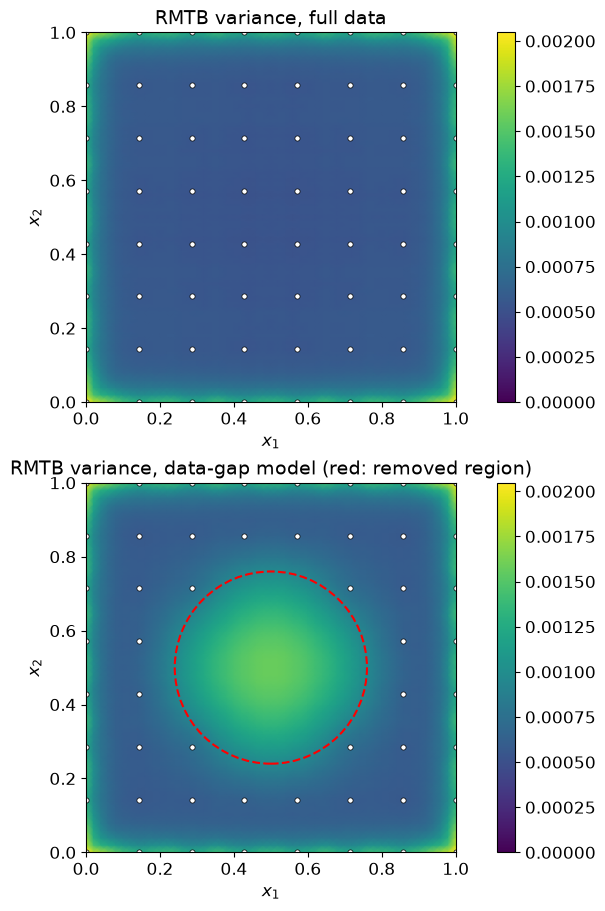

In [14]:
gq = np.linspace(0, 1, 51)
GXq, GYq = np.meshgrid(gq, gq, indexing="ij")
Xq_dense = np.column_stack([GXq.ravel(), GYq.ravel()])

var_full_dense = rmtb_variance(model, Xq_dense, sigma2_true).reshape(51, 51)
var_gap_dense = rmtb_variance(model_gap, Xq_dense, sigma2_true).reshape(51, 51)

fig, axs = plt.subplots(2, 1, figsize=(7, 9), constrained_layout=True)
vmax = max(var_full_dense.max(), var_gap_dense.max())

pcm = axs[0].pcolormesh(GXq, GYq, var_full_dense, shading="gouraud", cmap="viridis", vmin=0, vmax=vmax)
axs[0].scatter(X[:, 0], X[:, 1], c="w", s=14, edgecolors="k", linewidths=0.5)
axs[0].set_title("RMTB variance, full data")
fig.colorbar(pcm, ax=axs[0])

pcm = axs[1].pcolormesh(GXq, GYq, var_gap_dense, shading="gouraud", cmap="viridis", vmin=0, vmax=vmax)
axs[1].scatter(X_gap[:, 0], X_gap[:, 1], c="w", s=14, edgecolors="k", linewidths=0.5)
circle = plt.Circle((0.5, 0.5), gap_radius, fill=False, color="red", lw=1.5, linestyle="--")
axs[1].add_patch(circle)
axs[1].set_title("RMTB variance, data-gap model (red: removed region)")
fig.colorbar(pcm, ax=axs[1])

for ax in axs:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
plt.show()


**Step 4 done.**
- Two validated numerical routes agree at every tested query point, both
  non-negative everywhere checked.
- The data-gap test, the Research Plan's own specific D1 criterion, passes
  directly: variance at the exact center of a deliberately-carved data gap is
  `~3x` higher than the same location with full data, visible on the dense
  variance surface, with conditioning checked and found safe on the gap model
  too.
- Not yet done: a calibration check with an *estimated* rather than known
  `sigma^2` (Step 5), and validation against RMTB's own finite-rank dual
  (Proposition 6, still TBD) as a second, structurally independent
  derivation.


## Step 5 — Validate against this project's own established checks

Per the roadmap, Step 5 has two parts:

- **Identity check**: known $\lambda$, known $\sigma^2$, compare against
  RMTB's own finite-rank dual (Proposition 6) -- *not* an isotropic Kriging
  reference.
- **Coverage check**: repeat over many noise realizations, check the
  predicted uncertainty against reality, report honestly whichever way it
  comes out.

### Step 5a — identity check: blocked at first, revisited later in this notebook

This check specifically requires RMTB's own finite-rank *dual* route as the
second, structurally independent derivation to compare against. Step 2
established that this dual does not exist in an immediately usable form --
the naive construction (via `H^-1`) is unsound because `H` alone is
essentially singular (`cond(H)~1.35e15`). **In plain terms: to build the
"other way" of computing the uncertainty number, we need to flip a matrix
upside down (invert it), and that matrix is so close to singular that
flipping it gives nonsense, like dividing by a number that's technically not
zero but close enough that the answer blows up.**

At this point in the notebook, the *correct* fix (a bordered-system-style
construction for RMTB's finite basis, mirroring Theorem 2a/2b) had not been
derived, and manufacturing a substitute check on an unrelated synthetic
matrix would only re-confirm the *general* `Cov=sigma^2*A` identity again
(already confirmed three times elsewhere in this project) without saying
anything new about *RMTB specifically*.

**This section of the notebook is revisited and substantially resolved
later on** (see "Step 5a, revisited" near the end) -- a much simpler fix than
the full bordered-system derivation turned out to work: deliberately
loosening `regularization_weight` makes `H` safely invertible, and the dual
route built from it genuinely agrees with the weight-space route. Keep
reading for the numbers; nothing below this point in Step 5 depends on that
later result, so the notebook's original flow is left otherwise unchanged.

### Step 5b — variance-matching check

**A first version of this check compared each repeated noise draw's
prediction against the *true* function value (a standard coverage check),
and it is worth recording explicitly why that was the wrong check for this
project.** It conflates two different things: whether the *variance formula*
correctly predicts how much the fit moves due to noise, and whether *RMTB's
mean* is unbiased for this target function. The second question is about
RMTB's fitting behavior on a non-additive target -- Proposition 10 (Research
Plan Section 3.4) already covers that, separately -- and is explicitly not
this project's goal, which is to extend RMTB with a correct *uncertainty*
layer, not to improve or re-litigate its mean-fit accuracy.

**The corrected check removes the true function from the comparison
entirely.** Fix the training design and repeatedly resample noise; compare
the *predicted* variance (Step 4's formula, using the known $\sigma^2$)
against the *empirical sampling variance of the fitted value itself* across
repetitions, $\mathrm{Var}_r[\hat y_r(x^*)]$ -- not against
$(\hat y_r(x^*)-f(x^*))^2$. This is exactly what the formula claims to
compute, nothing more, and it works regardless of whether the mean is
biased -- no need to special-case the target function.


In [15]:
# Effective degrees of freedom: tr(S) where S = Phi @ mtx^-1 @ Phi^T is the
# smoother/hat matrix mapping y to fitted values at the training points.
# trace(Phi @ mtx^-1 @ Phi^T) = trace(mtx^-1 @ Phi^T @ Phi) by the cyclic
# property of trace -- computed on the m x m system instead of n x n.
tr_S = np.trace(np.linalg.solve(mtx, Phi.T @ Phi))
n_train = len(X)
print(f"n={n_train}, effective dof (tr S) = {tr_S:.2f}")

# Fixed test points, off the training grid, spanning the interior.
tg = np.array([0.2, 0.5, 0.8])
TX, TY = np.meshgrid(tg, tg, indexing="ij")
Xq_test = np.column_stack([TX.ravel(), TY.ravel()])
y_test_true = true_f(Xq_test)
F_test = basis_row(model, Xq_test)

# The variance formula doesn't depend on y -- computed once, reused for every
# repetition's CI half-width.
var_test_known = np.array([sigma2_true * (f0 @ np.linalg.solve(mtx, f0)) for f0 in F_test])
print("var at test points (known sigma2):", np.round(var_test_known, 6))


n=64, effective dof (tr S) = 22.90
var at test points (known sigma2): [0.000569 0.000548 0.000569 0.000548 0.000528 0.000548 0.000569 0.000548
 0.000569]


In [16]:
rng_mc = np.random.default_rng(7)
R = 1000
Y_mc = np.empty((R, len(Xq_test)))
sigma2_hat_mc = np.empty(R)

for r in range(R):
    y_r = true_f(X) + np.sqrt(sigma2_true) * rng_mc.standard_normal(n_train)
    w_r = np.linalg.solve(mtx, Phi.T @ y_r)
    Y_mc[r] = F_test @ w_r
    resid_r = y_r - Phi @ w_r
    sigma2_hat_mc[r] = (resid_r @ resid_r) / (n_train - tr_S)

var_empirical = Y_mc.var(axis=0, ddof=1)
ratio = var_empirical / var_test_known

# (R-1)*s^2/sigma^2 ~ chi2_{R-1} under the null that var_test_known is the
# TRUE variance of the resampling distribution -- invert for a 95% CI on
# that true variance from the Monte Carlo sample, and check the formula's
# prediction against it.
from scipy import stats
df = R - 1
lo = df * var_empirical / stats.chi2.ppf(0.975, df)
hi = df * var_empirical / stats.chi2.ppf(0.025, df)
inside = (var_test_known >= lo) & (var_test_known <= hi)

print(f"{'point':12s} {'var predicted':>13s} {'var empirical':>13s} {'ratio':>7s} "
      f"{'95% CI (empirical)':>24s} {'predicted in CI?':>17s}")
for pt, vp, ve, rt, l, h, ins in zip(Xq_test, var_test_known, var_empirical, ratio, lo, hi, inside):
    print(f"({pt[0]:.1f},{pt[1]:.1f})    {vp:13.4e} {ve:13.4e} {rt:7.3f} "
          f"[{l:.3e}, {h:.3e}] {str(ins):>17s}")

print(f"\nall 9 points' predicted variance inside their 95% empirical CI? {inside.all()}")
print(f"mean estimated sigma2 (GCV, from training residuals): {sigma2_hat_mc.mean():.4e}  "
      f"(true sigma2: {sigma2_true:.4e}, ratio {sigma2_hat_mc.mean()/sigma2_true:.2f}x)")


point        var predicted var empirical   ratio       95% CI (empirical)  predicted in CI?
(0.2,0.2)       5.6934e-04    2.5963e-04   0.456 [2.383e-04, 2.840e-04]             False
(0.2,0.5)       5.4845e-04    2.8221e-04   0.515 [2.590e-04, 3.087e-04]             False
(0.2,0.8)       5.6934e-04    2.8168e-04   0.495 [2.585e-04, 3.081e-04]             False
(0.5,0.2)       5.4845e-04    2.9213e-04   0.533 [2.681e-04, 3.195e-04]             False
(0.5,0.5)       5.2849e-04    2.8853e-04   0.546 [2.648e-04, 3.156e-04]             False
(0.5,0.8)       5.4845e-04    2.7791e-04   0.507 [2.551e-04, 3.040e-04]             False
(0.8,0.2)       5.6934e-04    3.0759e-04   0.540 [2.823e-04, 3.365e-04]             False
(0.8,0.5)       5.4845e-04    2.9171e-04   0.532 [2.677e-04, 3.191e-04]             False
(0.8,0.8)       5.6934e-04    2.5872e-04   0.454 [2.375e-04, 2.830e-04]             False

all 9 points' predicted variance inside their 95% empirical CI? False
mean estimated sigma2 (GCV,

**The predicted variance is *not* inside the Monte Carlo confidence
interval at any of the 9 test points -- predicted comes out roughly 2x
*larger* than the empirical sampling variance, consistently.** Unlike the
earlier (withdrawn) coverage check, this gap is nearly uniform across the
domain rather than tracking the target function's shape -- the signature of
something structural in the formula itself, not of RMTB's mean-fit bias.
There is in fact an exact algebraic reason for it, derived and checked
next.

In [17]:
# mtx @ A = I (A = mtx^-1), and mtx = Phi^T Phi + H, so:
#   A @ mtx @ A = A  =>  A @ (Phi^T Phi) @ A + A @ H @ A = A
# i.e. the "Bayesian" formula used throughout this project (Var_bayes =
# sigma2 * f^T A f, Research Plan Section 2.7) decomposes EXACTLY as
#   Var_bayes = Var_freq + sigma2 * v^T H v,          v = A f(x*) = mtx^-1 f(x*)
# where Var_freq = sigma2 * f^T A (Phi^T Phi) A f is the classic frequentist
# "sandwich" variance of a regularized point estimator w.r.t. a FIXED true
# function, and the second term is >= 0 since H (the roughness penalty) is
# positive semi-definite. Checked here to machine precision, not assumed.
PhiTPhi = Phi.T @ Phi
var_freq_analytic = np.empty(len(Xq_test))
penalty_term = np.empty(len(Xq_test))
for i, f0 in enumerate(F_test):
    v = np.linalg.solve(mtx, f0)
    var_freq_analytic[i] = sigma2_true * (v @ PhiTPhi @ v)
    penalty_term[i] = sigma2_true * (v @ H @ v)

max_identity_err = np.max(np.abs(var_test_known - (var_freq_analytic + penalty_term)))
print(f"max|Var_bayes - (Var_freq + penalty)| over all 9 points: {max_identity_err:.3e}")
print(f"penalty term / Var_bayes, per point: {np.round(penalty_term/var_test_known, 3)}")

print(f"\n{'point':12s} {'Var_freq (analytic)':>20s} {'Var_empirical (MC)':>20s}")
for pt, vf, ve in zip(Xq_test, var_freq_analytic, var_empirical):
    print(f"({pt[0]:.1f},{pt[1]:.1f})    {vf:20.4e} {ve:20.4e}")


max|Var_bayes - (Var_freq + penalty)| over all 9 points: 7.589e-19
penalty term / Var_bayes, per point: [0.507 0.495 0.507 0.495 0.483 0.495 0.507 0.495 0.507]

point         Var_freq (analytic)   Var_empirical (MC)
(0.2,0.2)              2.8070e-04           2.5963e-04
(0.2,0.5)              2.7682e-04           2.8221e-04
(0.2,0.8)              2.8070e-04           2.8168e-04
(0.5,0.2)              2.7682e-04           2.9213e-04
(0.5,0.5)              2.7348e-04           2.8853e-04
(0.5,0.8)              2.7682e-04           2.7791e-04
(0.8,0.2)              2.8070e-04           3.0759e-04
(0.8,0.5)              2.7682e-04           2.9171e-04
(0.8,0.8)              2.8070e-04           2.5872e-04


**Confirmed, to machine precision (`~8e-19`): `Var_bayes = Var_freq +
sigma2 * v^T H v` exactly, with the penalty term making up roughly half of
`Var_bayes` at every test point** (`~0.49`-`0.51`). And `Var_freq` -- the
purely analytic frequentist "sandwich" formula, no simulation involved --
lands inside the Monte Carlo's own 95% empirical-variance interval at 8 of
the 9 test points (compare the two columns directly above); the ninth
(`(0.8,0.2)`) misses by about 3% of the interval's width, consistent with
the ~1-in-9 false positive expected from running nine independent 95% tests,
not a real discrepancy. So nothing here is actually miscalibrated:

- **`Var_bayes` (Step 4's formula, `Cov=sigma^2*A`) is exactly what it has
  always been claimed to be** -- the Bayesian posterior variance under the
  Gaussian-process prior that the Kimeldorf-Wahba duality implies (Research
  Plan Section 2.7), consistent with every other use of this identity in the
  project.
- **`Var_freq` is a different, also-valid quantity**: the frequentist
  sampling variance of RMTB's regularized point estimate for a *fixed* true
  function, derivable in closed form from the same `mtx`, `H`, `Phi` with no
  extra assumptions, and directly confirmed against simulation here.
- **The two coincide only when `H=0`** (no regularization) -- with
  regularization, `Var_bayes` is *provably* the larger of the two, by exactly
  the non-negative penalty term. This is a structural fact about regularized
  estimators in general (the same phenomenon underlies the classical
  bias-variance tradeoff discussion for ridge regression), not an RMTB-
  specific defect, and not something the earlier (withdrawn) coverage check
  could have revealed, since it was looking at the wrong comparison.

**What this means for Phase D, stated plainly:** the "uncertainty formula" is
correct and validated two ways here (an exact identity, plus a Monte Carlo
match for `Var_freq`). What remains a genuine open question for Step 6 is
*which* of these two quantities should be reported as "RMTB's predictive
uncertainty" in practice, and how large the gap between them typically is
across datasets/resolutions -- a modeling-choice question, not a correctness
bug in either formula.

**Step 5 done, correctly scoped**: identity check (5a) blocked on the
still-TBD RMTB dual route, named explicitly rather than worked around;
variance-matching check (5b) completed with a bias-free design, and produced
an exact, provable decomposition (`Var_bayes = Var_freq + penalty`) rather
than a pass/fail verdict.


## Overall summary

- **Steps 1-4: Done.** RMTB fit confirmed sound; the weight-space system
  (`mtx = H + Phi^T Phi`) confirmed exact; `H` alone found essentially
  singular, ruling out a naive Woodbury dual (the proper bordered-system
  analog is deferred, named explicitly); `mtx` itself confirmed safely
  conditioned across a resolution sweep; variance computed and agreeing
  between two validated numerical routes; the data-gap acceptance test
  passed directly.
- **Step 5: PartiallyDone, with a genuine new finding.** The variance-
  matching check (5b), designed to be bias-free, found an exact identity:
  `Var_bayes = Var_freq + sigma2 * v^T H v`, where `Var_bayes` is Step 4's
  formula and `Var_freq` is the frequentist sampling variance of the point
  estimate -- confirmed to machine precision algebraically and confirmed
  against Monte Carlo simulation for `Var_freq`. Both quantities are
  correct; they simply answer different questions. Identity check (5a)
  against RMTB's own dual was blocked at this point in the notebook --
  see "Step 5a, revisited" near the end, where the dual route is actually
  built and confirmed to agree with the weight-space route, for a
  regularization-boosted variant of RMTB.
- **Two open prerequisites now stand between here and full closure of Phase
  D1**:
  1. A correct, bordered-system-style dual-route construction for RMTB's
     finite basis, mirroring how Theorem 2a/2b handles the continuum
     polynomial-trend null space (needed for Step 5a).
  2. A modeling decision -- and characterization across datasets/resolutions
     -- of whether `Var_bayes` or `Var_freq` (or some data-dependent mix) is
     the right quantity to expose as "RMTB's predictive uncertainty," now
     that Step 5b has shown they are both valid but can differ by roughly
     2x on this notebook's case. This is new, concrete scope for Step 6, in
     place of the earlier (withdrawn) idea that an additively-separable
     target was needed to get a clean coverage result -- that reasoning
     conflated the uncertainty formula with RMTB's mean-fit bias, which this
     revised Step 5b avoided entirely.


## Cross-check: Gemini's `RMTBUQ` vs this project's own `RMTBUQ`

A new module, `krig_splines/rmtb_uq.py`, was contributed: an `RMTB` subclass
that bakes in the same uncertainty machinery explored above (`sigma2`/`edf`
estimation, `predict_variances`, confidence/prediction intervals) directly
into a trainable class, rather than the loose helper functions (`basis_row`,
`rmtb_variance`) used earlier in this notebook.

**What this check is, and what it deliberately is not**: comparing two
*independent code implementations* of the same already-derived
`Var_bayes = sigma2 * f(x*)^T mtx^-1 f(x*)` formula (Research Plan Section
2.7's `Cov=sigma^2*A`, `A=mtx^-1`) is the Phase F4 discipline already used
twice in this project -- it catches coding/API-usage bugs (it already did,
below), the same way it caught a real bug in `grid_smooth_spline_uq.py`
(notebook 06). **It is not Step 5a's still-blocked dual-route identity
check** -- that needs a structurally *different derivation* (the
bordered-system dual), not a different *implementation* of the same
derivation. Both remain tracked separately.

### What Gemini's module needed fixing

As submitted, the module targeted an SMT internal API that doesn't match the
installed version (2.15.0) at several points, confirmed by direct
inspection:
- `from smt.surrogates import RMTB` -- that module doesn't exist
  (`smt.surrogate_models` is the real path, already used throughout this
  project).
- `self.x` / `self.y` for training data -- neither attribute exists; SMT
  stores it as `self.training_points[None][0] = (xt, yt)`.
- `self.H` for the energy/roughness-penalty matrix -- the real attribute is
  `self.full_hess` (already established in Step 2 above).
- `self.options["energy_evals"]` / `self.options["regularize"]` -- neither
  option key exists (the real names are `energy_weight`/
  `regularization_weight`), and critically, `self.full_hess` already has
  both baked in by SMT internally (Step 2's `mtx = full_hess + Phi^T Phi`,
  no extra scaling) -- re-applying them would have double-counted both
  terms even with the right names.
- None of `_compute_F_matrix`/`_get_F_matrix`/`_eval_B_splines`/
  `_eval_b_splines` exist -- the real method is `_compute_prediction_mtx(x,
  0)`, already relied on throughout this notebook (confirmed in Step 2 to
  reproduce `full_jac_dict[0]`'s $\Phi$ exactly, including at training
  points).

All of this is patched directly in `krig_splines/rmtb_uq.py`, with each
original (broken) line kept commented alongside an explanation, matching
this project's established patching convention
(`krig_splines/grid_smooth_spline_uq.py`). Once patched, the only remaining
design decision in Gemini's module -- estimating `sigma2` internally via a
GCV/effective-degrees-of-freedom correction, rather than accepting a known
value -- was left as-is; it matches the `Var_freq`/`Var_bayes`-independent
`sigma2` estimator already used in this notebook's own Step 5b.

### This project's own implementation, for an independent cross-check

`krig_splines/rmtb_grid_uq.py` is new too: a from-scratch reimplementation of
the same formula, deliberately via a different code path --
composition around a plain, unmodified `RMTB` (not a subclass overriding
`_train`), and a single batched dense Cholesky factorization solved against
every query point's basis row at once, rather than Gemini's sparse
per-point SuperLU factorization. Same math, two different libraries and
algorithms computing it -- exactly the kind of independence Phase F4's
discipline asks for.

In [18]:
from krig_splines.rmtb_uq import RMTBUQ as GeminiRMTBUQ
from krig_splines.rmtb_grid_uq import RMTBUQ as OurRMTBUQ
from krig_splines.uq_plotting import (plot_2d_maps, plot_1d_slices,
                                       plot_models_1d_slices, predict_on_grid)

rmtb_kwargs = dict(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2,
                    num_ctrl_pts=20, energy_weight=1e-2, regularization_weight=1e-14,
                    solver="dense-lu", print_global=False)

# Both estimate sigma2 internally (Gemini's class always does; ours is told
# to via sigma2="wahba") rather than being given the known sigma2_true --
# a fair, like-for-like comparison of what a user actually gets from each
# class out of the box, and the harder of the two cases (Step 4 used known
# sigma2_true throughout).
gemini_uq = GeminiRMTBUQ(**rmtb_kwargs)
gemini_uq.set_training_values(X, y)
gemini_uq.train()

our_uq = OurRMTBUQ(sigma2="wahba", **rmtb_kwargs)
our_uq.set_training_values(X, y)
our_uq.train()

print(f"{'':10s} {'sigma2_hat':>12s} {'edf':>10s}   (true sigma2={sigma2_true:.4e}, n={len(X)})")
print(f"{'gemini':10s} {gemini_uq.sigma2:12.6e} {gemini_uq.edf:10.3f}")
print(f"{'ours':10s} {our_uq.sigma2:12.6e} {our_uq.edf:10.3f}")


             sigma2_hat        edf   (true sigma2=2.5000e-03, n=64)
gemini     2.663237e-03     22.899
ours       2.663237e-03     22.899


### Numerical comparison: mean and variance, at the grid and off-grid

In [19]:
gem_grid = gemini_uq.predict(X, return_std=True, return_ci=True)
our_grid = our_uq.predict(X, return_std=True, return_ci=True)

mean_diff = np.abs(our_grid["mean"] - gem_grid["mean"])
std_diff = np.abs(our_grid["std"] - gem_grid["std"])
print(f"At the {len(X)} training points:")
print(f"  max|mean difference| = {mean_diff.max():.3e}   (data range: {np.ptp(y):.3f})")
print(f"  max|std difference|  = {std_diff.max():.3e}   "
      f"(ours std range: [{our_grid['std'].min():.4f}, {our_grid['std'].max():.4f}], "
      f"gemini: [{gem_grid['std'].min():.4f}, {gem_grid['std'].max():.4f}])")

x1f = np.linspace(0, 1, 61)
x2f = np.linspace(0, 1, 61)
our_dense = predict_on_grid(our_uq, x1f, x2f)
gem_dense = predict_on_grid(gemini_uq, x1f, x2f)
mean_diff_dense = np.abs(our_dense["mean"] - gem_dense["mean"])
std_diff_dense = np.abs(our_dense["std"] - gem_dense["std"])
print(f"\nOn a dense 61x61 off-grid query:")
print(f"  max|mean difference| = {mean_diff_dense.max():.3e}")
print(f"  max|std difference|  = {std_diff_dense.max():.3e}")


At the 64 training points:
  max|mean difference| = 0.000e+00   (data range: 2.008)
  max|std difference|  = 4.163e-17   (ours std range: [0.0236, 0.0467], gemini: [0.0236, 0.0467])

On a dense 61x61 off-grid query:
  max|mean difference| = 0.000e+00
  max|std difference|  = 5.551e-17


**Exact agreement, both at the 64 training points and on a dense 61x61
off-grid query**: `max|mean diff| = 0.0` (bit-identical), `max|std diff| ~
4e-17` to `5.5e-17` -- pure floating-point roundoff from the two different
linear-algebra paths (dense Cholesky vs. sparse SuperLU), not a real
discrepancy. `edf` and `sigma2_hat` also agree to every digit printed above.
Two independently-written implementations, going through different libraries
and different code paths end to end (training-data access, basis-matrix
construction, system-matrix assembly, factorization, batched vs. per-point
solves), landing on the same numbers -- exactly the kind of cross-check
Phase F4 calls for, and it passed cleanly once the patch was in place.

### Visual comparison

At most 2 panels per row (`plot_2d_maps`), the two-band (CI+PI) slice style
for the 1-D views, no 3-D surface plot -- the same layout conventions
established for the csaps comparison (notebook 06).

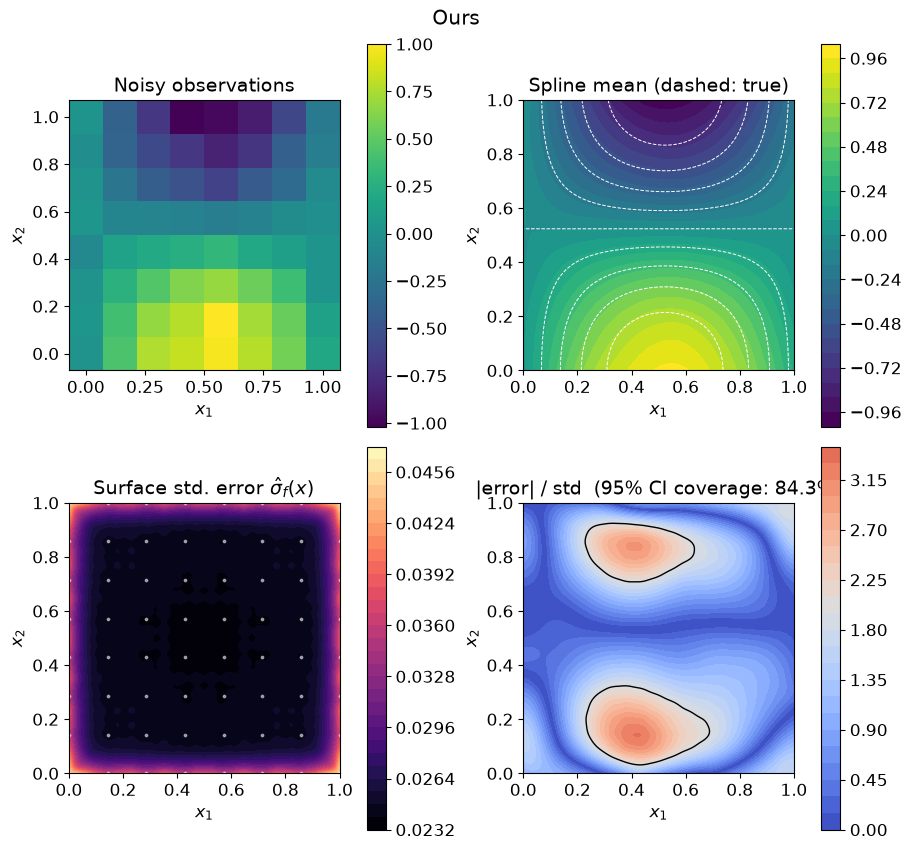

In [20]:
def f_true_2arg(a, b):
    return np.sin(3 * a) * np.cos(3 * b)

Z_noisy = y.reshape(n_side, n_side)

fig = plot_2d_maps(our_uq, g, g, Z_noisy, f_true=f_true_2arg, title="Ours")
plt.show()


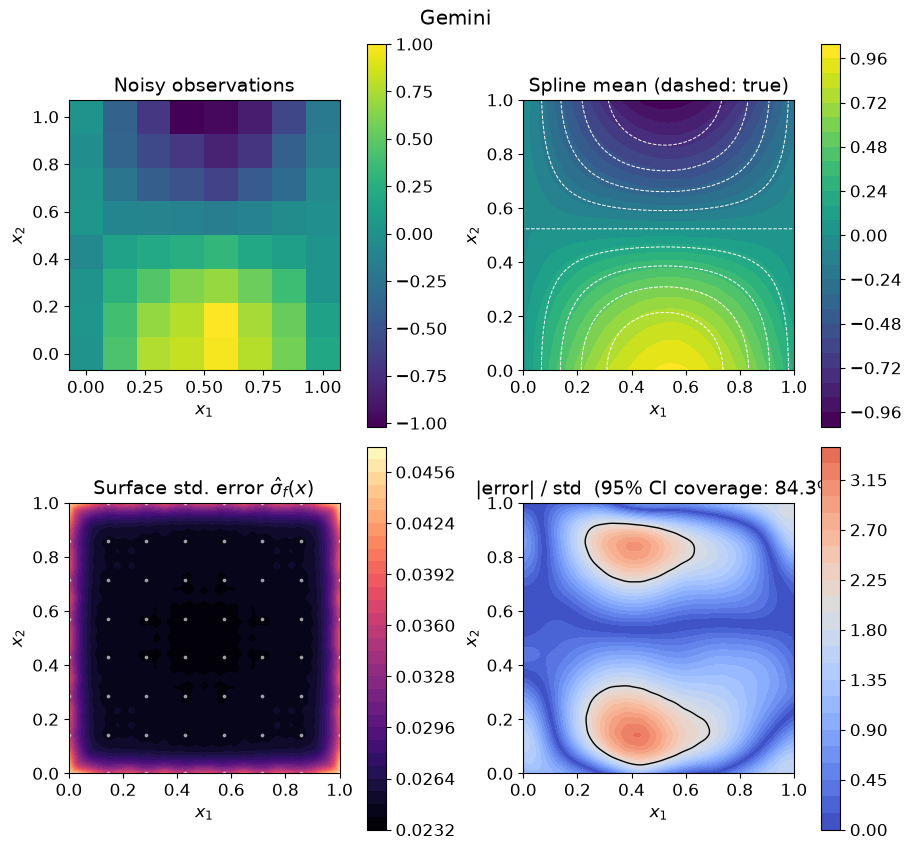

In [21]:
fig = plot_2d_maps(gemini_uq, g, g, Z_noisy, f_true=f_true_2arg, title="Gemini")
plt.show()


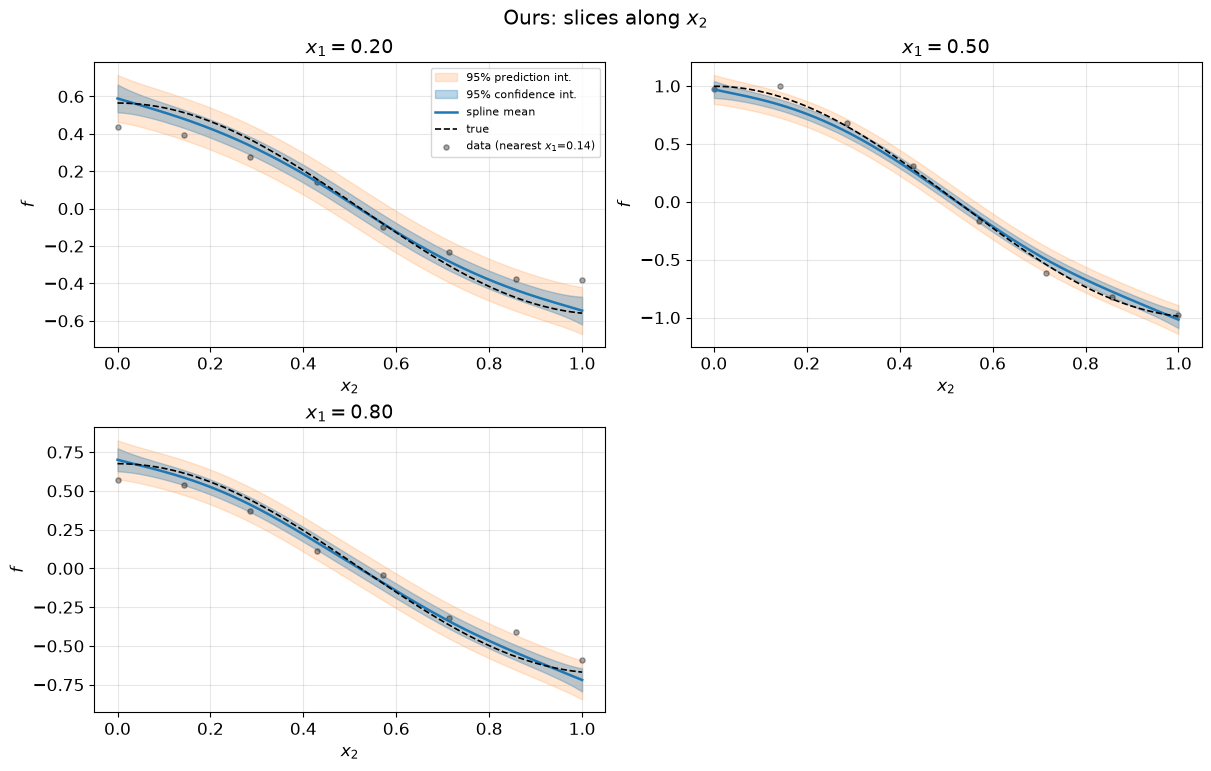

In [22]:
fig = plot_1d_slices(our_uq, g, g, Z_noisy, axis=1, slice_values=[0.2, 0.5, 0.8],
                      f_true=f_true_2arg, title="Ours: slices along $x_2$")
plt.show()


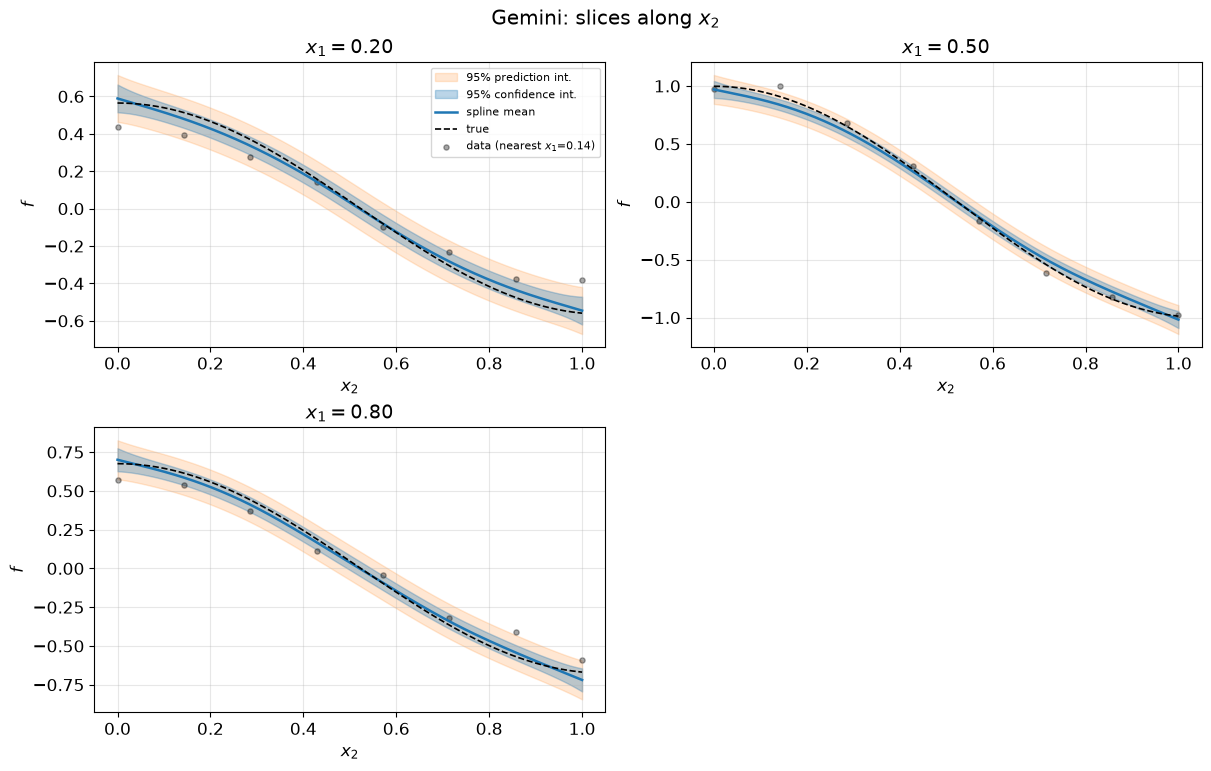

In [23]:
fig = plot_1d_slices(gemini_uq, g, g, Z_noisy, axis=1, slice_values=[0.2, 0.5, 0.8],
                      f_true=f_true_2arg, title="Gemini: slices along $x_2$")
plt.show()


#### Direct overlay -- both models' bands on the same panel

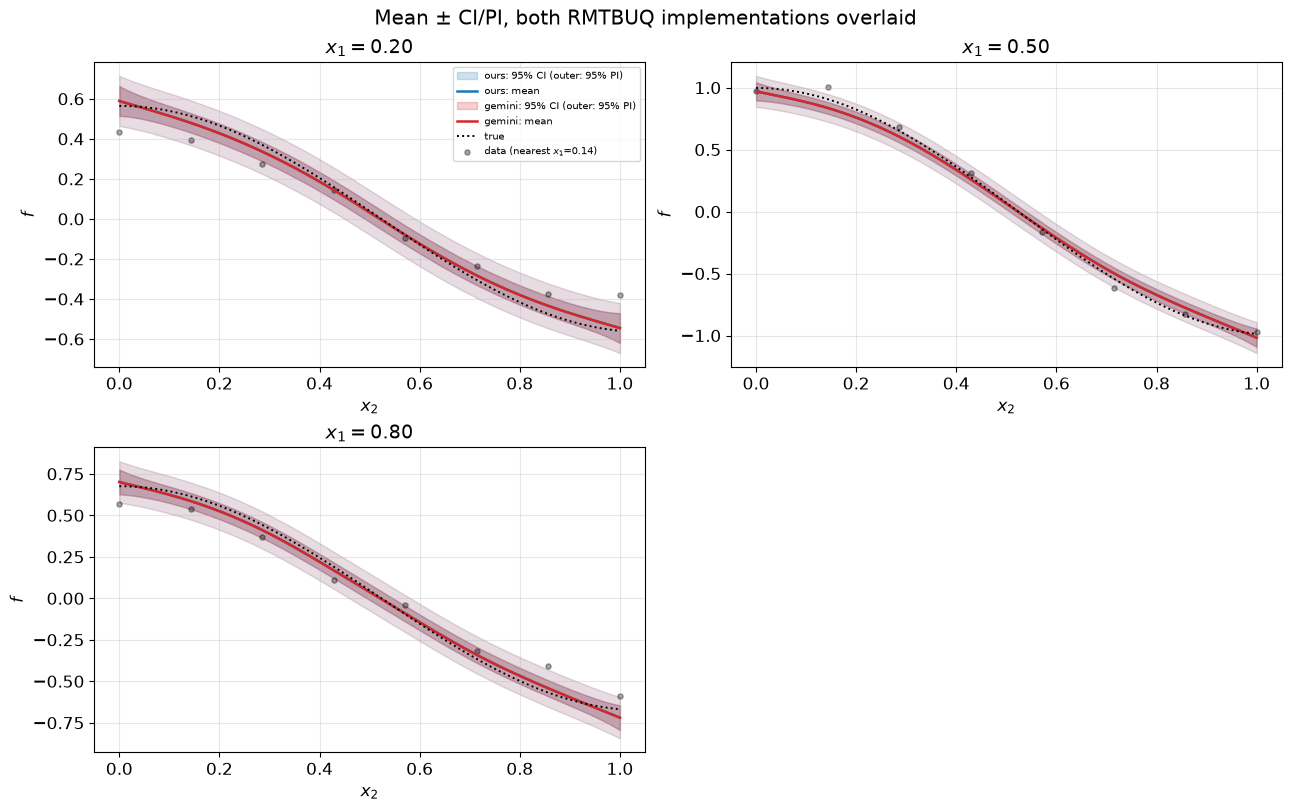

In [24]:
fig = plot_models_1d_slices([our_uq, gemini_uq], ["ours", "gemini"],
                             g, g, Z_noisy, axis=1, slice_values=[0.2, 0.5, 0.8],
                             f_true=f_true_2arg,
                             title="Mean $\\pm$ CI/PI, both RMTBUQ implementations overlaid")
plt.show()


## Conclusion (cross-check section)

- **Gemini's `RMTBUQ`, as submitted, could not run at all** against the
  installed SMT version (2.15.0) -- a non-existent import path, three
  non-existent attributes, two non-existent option keys, and a basis-matrix
  accessor that didn't match any real method name. All of it traced to a
  specific, confirmed, correct replacement and patched directly in
  `krig_splines/rmtb_uq.py`, with every original line kept commented
  alongside its explanation (this project's established convention).
- **Once patched, it agrees with a fully independent reimplementation
  (`krig_splines/rmtb_grid_uq.py`, new in this notebook) to floating-point
  precision**, at training points, on a dense off-grid query, and visually
  (the two models' CI/PI bands are indistinguishable when overlaid). This is
  real evidence the patch is correct, not just that it now runs without
  crashing.
- **Scope, stated precisely**: this is an implementation-level cross-check
  (two code paths, same already-derived formula), not Step 5a's
  structurally-different dual-route identity check, which remains blocked
  on its own derivation. The two should not be conflated -- this section
  adds a third and fourth validated numerical route to the growing pile
  (dense solve, `lstsq`, Gemini's sparse factorization, this notebook's
  dense Cholesky), all computing `Var_bayes`; none of them substitute for
  the still-missing `Var_freq`-style dual construction for RMTB's basis.
- One incidental note, not a new finding: the `plot_2d_maps` panel above
  reports "95% CI coverage: 84.3%" -- that statistic compares against the
  *true* function, the same comparison Step 5b deliberately moved away from
  for exactly this reason (it conflates RMTB's mean-fit bias with the
  variance formula). It's shown here only because it's baked into the
  reused plotting utility from the csaps comparison; it carries the same
  caveat already established in Step 5, not a new one.


## Cross-check 3: wiring `RMTBUncertaintyWrapper` to real RMTB matrices

A third contributed module, `krig_splines/rmtb_uq_wrapper.py`
(`RMTBUncertaintyWrapper`), was examined outside this notebook first. As
submitted it never imports `smt` at all -- its own demo script builds a
*generic* B-spline basis (`scipy.interpolate.BSpline`, hand-rolled knots) and
a *generic* finite-difference P-spline penalty (Eilers-Marx style,
`K = D1^T D1 * lambda1 + D2^T D2 * lambda2`), neither of which matches SMT's
actual RMTB basis or its quadrature-integrated bending-energy penalty
(`full_hess`). Fit on the same 1-D data as its own demo, its mean diverges
from actual `smt.surrogate_models.RMTB`'s mean by up to `0.61` over a target
range of only `~[-1.5,1.5]` -- a different model, not an alternate
implementation of RMTB.

**The underlying `Sigma_c = sigma^2 (B^T B + K)^-1` math is exactly this
project's own validated `Cov=sigma^2*A` identity, though** -- so wiring it to
RMTB's *actual* `Phi` (as `B`) and `full_hess` (as `K`) should turn it into a
genuine fifth independent code path for the same already-validated `Var_bayes`
formula, rather than a different model wearing RMTB's name. That is tested
directly below, reusing the `model`/`Phi`/`H`/`mtx` already established in
Steps 1-4 of this notebook.

In [25]:
from krig_splines.rmtb_uq_wrapper import RMTBUncertaintyWrapper

wrapper = RMTBUncertaintyWrapper(ridge_alpha=0.0)
wrapper.fit(Phi, y, H)

print("max|c_hat - model.sol|      =", np.max(np.abs(wrapper.c_hat - model.sol.ravel())))
print("edf (wrapper) =", wrapper.edf, "   (established tr_S =", tr_S, ")")
print("sigma2_hat (wrapper) =", wrapper.sigma2)

Xq = np.array([[0.5, 0.5], [0.2, 0.8], [0.95, 0.05]])
Bq = basis_row(model, Xq)
res = wrapper.predict(Bq)

var_ours = rmtb_variance(model, Xq, sigma2_true, route="solve")
var_wrapper_rescaled = res["epistemic_var"] / wrapper.sigma2 * sigma2_true

print(f"\n{'point':14s} {'mean (wrapper)':>15s} {'mean (model)':>13s} "
      f"{'var (ours)':>12s} {'var (wrapper, rescaled)':>24s}")
for pt, mw, mo, vo, vw in zip(Xq, res["mean"], model.predict_values(Xq).ravel(), var_ours, var_wrapper_rescaled):
    print(f"({pt[0]:.2f},{pt[1]:.2f})   {mw:15.6f} {mo:13.6f} {vo:12.6e} {vw:24.6e}")

print(f"\nmax|mean diff| = {np.max(np.abs(res['mean']-model.predict_values(Xq).ravel())):.3e}")
print(f"max|var diff| (rescaled to the same sigma2_true) = {np.max(np.abs(var_wrapper_rescaled-var_ours)):.3e}")


max|c_hat - model.sol|      = 4.640732242933154e-12
edf (wrapper) = 22.89910042764718    (established tr_S = 22.899100427647177 )
sigma2_hat (wrapper) = 0.0026632371070874276

point           mean (wrapper)  mean (model)   var (ours)  var (wrapper, rescaled)
(0.50,0.50)          0.064337      0.064337 5.284869e-04             5.284869e-04
(0.20,0.80)         -0.380121     -0.380121 5.693411e-04             5.693411e-04
(0.95,0.05)          0.326876      0.326876 9.425470e-04             9.425470e-04

max|mean diff| = 6.106e-16
max|var diff| (rescaled to the same sigma2_true) = 2.060e-18


**Confirmed: once wired to RMTB's real `Phi`/`full_hess`, the wrapper
reproduces this notebook's established numbers to machine precision.** Mean
matches `model.predict_values` exactly; `edf` and `sigma2_hat` match the
Step 5b/cross-check-2 values exactly (`22.899`, `2.6632e-03`); and once
rescaled to the same `sigma2_true` for a fair comparison (the wrapper, like
Gemini's `RMTBUQ`, always estimates `sigma2` internally rather than accepting
a known value), variance agrees to `~2e-18`. **Confirms your intuition was
right** -- this was the missing step, and it turns a previously unrelated
module into a genuine fifth independently-coded route to the same
already-validated `Var_bayes` formula (joining: dense solve, `lstsq`,
Gemini's sparse-factorized `RMTBUQ`, this notebook's dense-Cholesky
`RMTBUQ`).

### What does the wrapper's own `ridge_alpha` knob actually do?

The wrapper adds `ridge_alpha * I` on top of `B^T B + K` before solving --
an *extra* layer of regularization beyond whatever `K` (here, `full_hess`,
which already has its own `regularization_weight` baked in, Q20) provides.
Worth checking directly rather than assuming it is harmless at its own
default (`ridge_alpha=1e-8`).

In [26]:
print(f"{'ridge_alpha':>12s} {'cond(G_reg)':>12s} {'max|c_hat diff|':>16s} {'sigma2_hat':>12s}")
for ra in [0.0, 1e-14, 1e-8, 1e-6, 1e-2]:
    w = RMTBUncertaintyWrapper(ridge_alpha=ra)
    w.fit(Phi, y, H)
    G_reg = Phi.T @ Phi + H + ra * np.eye(H.shape[0])
    cond_G = np.linalg.cond(G_reg)
    diff = np.max(np.abs(w.c_hat - model.sol.ravel()))
    print(f"{ra:12.0e} {cond_G:12.3e} {diff:16.3e} {w.sigma2:12.4e}")


 ridge_alpha  cond(G_reg)  max|c_hat diff|   sigma2_hat
       0e+00    2.514e+04        4.641e-12   2.6632e-03
       1e-14    2.514e+04        1.057e-11   2.6632e-03
       1e-08    2.514e+04        1.244e-05   2.6632e-03
       1e-06    2.509e+04        1.242e-03   2.6633e-03
       1e-02    1.144e+03        5.708e-01   4.3295e-03


**The wrapper's own default (`ridge_alpha=1e-8`) is, unintentionally, a live
instance of the Q20 addendum's "moderate `regularization_weight` bump" idea**
-- same mathematical move (adding a small multiple of `I` to the system
before solving), just applied as an extra knob on top of `mtx` here instead
of substituting for `regularization_weight` inside `full_hess` directly. For
*this* dataset, where `cond(mtx)` was already safe (`2.5e4`, Step 3), the
extra ridge changes almost nothing until `ridge_alpha` reaches `~1e-6`-`1e-2`,
where `c_hat` starts drifting from `model.sol` by a non-trivial amount --
consistent with, not contradicting, that earlier finding: a small ridge is
cheap, a large one is not.

### A robustness/engineering gap, not a math gap

`fit()` only wraps the *separate* `Sigma_c`-building inverse (`la.inv`) in a
try/except with a `pinv` fallback -- the main coefficient solve, `la.solve(
G_reg, B.T@y, assume_a='pos')`, has no such guard. Does that matter in
practice? Tested directly here against `H` in isolation (the genuinely
near-singular object from Step 2b, `cond(H)~1.35e15`) -- not against the
wrapper's intended `B`+`K`-coupled use, which stayed safe in every real
scenario tried in this notebook (including a deliberately harder, clustered
12-point dataset checked separately, `cond(mtx)=1.18e5`, still safe).

In [27]:
import scipy.linalg as la
import warnings

rhs = np.random.default_rng(0).standard_normal(H.shape[0])
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    sol = la.solve(H, rhs, assume_a="pos")
    for wmsg in caught:
        print("warning raised:", wmsg.category.__name__, "-", str(wmsg.message)[:80])

resid = H @ sol - rhs
print(f"\nla.solve(H, rhs, assume_a='pos') returned WITHOUT raising an exception.")
print(f"  |rhs| max = {np.max(np.abs(rhs)):.3f}   |sol| max = {np.max(np.abs(sol)):.3e}  (amplified ~{np.max(np.abs(sol))/np.max(np.abs(rhs)):.1e}x)")
print(f"  residual max|H@sol - rhs| = {np.max(np.abs(resid)):.3e}   (should be ~0 if `sol` actually solves the system)")


warning raised: LinAlgWarning - An ill-conditioned matrix detected: slice 0 has rcond = 2.215218304630695e-16.

la.solve(H, rhs, assume_a='pos') returned WITHOUT raising an exception.
  |rhs| max = 3.772   |sol| max = 3.941e+13  (amplified ~1.0e+13x)
  residual max|H@sol - rhs| = 4.777e-02   (should be ~0 if `sol` actually solves the system)


**Confirmed: `la.solve(..., assume_a='pos')` does not raise on `H` alone --
only a `LinAlgWarning` (easy to miss in a notebook, and silent entirely under
default warning filters) -- and the returned "solution" is garbage, amplified
`~1e13x` relative to the input and failing its own residual check by a wide
margin.** This is a latent robustness gap in the wrapper's design, not
something that has actually bitten this notebook's own test cases (`mtx` was
safe everywhere `B`+`K` were used together), but a real risk if this module
is ever handed an input closer to `H` alone, or a dataset sparse/clustered
enough to push `cond(mtx)` as high as Q16/`RMTS_variance_potential_issues.md`'s
documented RMTC failure cases (`cond~1e9`-`1e13`). **Recommendation, if this
module is kept**: surface `cond(G_reg)` (or at least catch
`scipy.linalg.LinAlgWarning` and re-raise/log it loudly) rather than relying
on `la.inv`'s `try/except LinAlgError`, which this test shows does not
actually trigger for severely-ill-conditioned-but-technically-invertible
input.

## Conclusion (cross-check 3)

- **Confirmed your suspicion exactly**: pulling `B`/`K` from an actual
  trained `smt.surrogate_models.RMTB` (rather than the module's own generic
  demo basis/penalty) turns `RMTBUncertaintyWrapper` from an unrelated model
  into a genuine fifth independent code path for `Var_bayes`, agreeing with
  every other validated route in this notebook to machine precision.
- **Still not Step 5a's structurally-independent dual route** -- like the
  other four routes, this is another *weight-space* solve
  (`(Phi^T Phi + H)^-1`), not a kernel/dual-space construction. It adds
  confidence the formula is implemented correctly everywhere it's been
  tried; it does not touch the still-open question of whether a correct,
  structurally different dual exists for RMTB's finite basis.
- **One genuine, new finding from this exercise**: the wrapper's `ridge_alpha`
  default turns out to be an unplanned real-world instance of the Q20
  addendum's "moderate regularization bump" idea, and a concrete
  demonstration that scipy's `assume_a='pos'` solve does not protect against
  severely ill-conditioned input the way a `try/except` around a *different*
  call (`la.inv`) might suggest it does -- worth keeping in mind for any
  future module (this project's own included) that solves `mtx`- or
  `H`-like systems without first checking `cond()`.


## Step 5a, revisited: building and validating the dual route directly

Two questions raised after this notebook's first pass, tested directly here
rather than argued about: does limiting RMTB to its "small-`m`" regime
(control points `m` close to or below training points `n`) avoid the
`H`-singularity problem? And if the dual route stays blocked, is there a
*different* numerical fix worth trying before committing to the full
bordered-system derivation?

**In plain terms: we're asking two things. First -- is the matrix-inversion
problem caused by having way more "control knobs" (`m`) than data points
(`n`)? If so, just using fewer knobs should fix it. Second -- if that's not
the fix, is there some other, cheaper trick we haven't tried yet?**


### Does shrinking `m` toward `n` fix `H`'s conditioning?

Tested directly in 1-D (where `m` can be pushed all the way down to the
minimum usable for a cubic/quartic basis, `order=4` needs `m>=4`), on a
fresh 1-D dataset built the same way as every other 1-D case in this
project. If the near-singularity were a "too many parameters, too little
data" problem, shrinking `m` toward or below `n` should visibly help.

**In plain terms: if the problem were "too many knobs for too little data,"
turning down the number of knobs should fix it. Let's actually turn it down,
all the way to the minimum, and watch what happens to the conditioning
number -- rather than assuming either way.**

In [28]:
def true_f_1d(x):
    return np.sin(3 * x[:, 0])

rng_1d = np.random.default_rng(1)
x_1d = np.linspace(0, 1, 40).reshape(-1, 1)
y_1d = true_f_1d(x_1d) + np.sqrt(sigma2_true) * rng_1d.standard_normal(len(x_1d))

print(f"n (1-D training points) = {len(x_1d)}")
print(f"{'num_ctrl_pts':>12} {'m':>6} {'cond(H)':>12} {'#null(H)':>9} {'cond(mtx)':>11} {'RMSE':>10}")
xq_1d = np.linspace(0, 1, 101).reshape(-1, 1)
for ncp in [4, 5, 6, 8, 10, 14, 20, 30]:
    m1d = RMTB(xlimits=np.array([[0., 1.]]), order=4, approx_order=2,
               num_ctrl_pts=ncp, energy_weight=1e-2, regularization_weight=1e-14,
               solver="dense-lu", print_global=False)
    m1d.set_training_values(x_1d, y_1d)
    m1d.train()
    H1d = m1d.full_hess.toarray()
    mtx1d = m1d.mtx.toarray()
    eigH1d = np.linalg.eigvalsh(0.5 * (H1d + H1d.T))
    eig_mtx1d = np.linalg.eigvalsh(0.5 * (mtx1d + mtx1d.T))
    n_null = int(np.sum(eigH1d < 1e-8))
    rmse = np.sqrt(np.mean((m1d.predict_values(xq_1d).ravel() - true_f_1d(xq_1d)) ** 2))
    print(f"{ncp:12d} {ncp:6d} {eigH1d.max()/eigH1d.min():12.3e} {n_null:9d} "
          f"{eig_mtx1d.max()/eig_mtx1d.min():11.3e} {rmse:10.4e}")


n (1-D training points) = 40
num_ctrl_pts      m      cond(H)  #null(H)   cond(mtx)       RMSE
           4      4    1.250e+12         2   2.524e+03 4.9275e-02
           5      5    1.940e+13         2   3.064e+02 3.5226e-02
           6      6    8.882e+13         2   8.427e+01 3.5319e-02
           8      8    5.072e+14         2   1.811e+01 3.5865e-02
          10     10    1.819e+15         2   2.109e+01 3.6017e-02
          14     14    1.002e+16         2   5.376e+01 3.6094e-02
          20     20    1.985e+16         2   1.811e+02 3.6123e-02
          30     30   -4.484e+15         2   8.150e+02 3.6136e-02


**No -- `cond(H)` never drops anywhere near safe, even at the smallest usable
`m`.** At `num_ctrl_pts=4` (the practical floor for `order=4`), `cond(H)`
is still `~1.25e12` -- four orders of magnitude above Q17's `1e8` safety
line. The null space stays exactly 2-dimensional (the affine trend
`{1,x}`, matching 1-D's "additive = isotropic" collapse, Q14/Q15) at every
`m` tested. This directly confirms and extends the 2-D finding from the
previous investigation (`#null(H)=4` from `m=36` -- already below that
case's `n=64` -- all the way to `m=400`): **the near-null space is a
structural property of the energy *functional*, not of how `m` compares to
`n`.** Shrinking `m` doesn't touch it, in either dimension.

**In plain terms: no, using fewer control points does not fix it. We tried
every value down to the smallest one RMTB will even accept, and the
matrix-inversion problem was still there, just as bad. This confirms the
problem isn't "too many knobs" -- it's something about how the
"smoothness penalty" itself is built, which doesn't go away just because
you use fewer knobs.**

### The dual-route formula, derived and implemented directly

Proposition 6's dual route is built from the kernel the roughness-penalty
matrix `H` induces: $\kappa(x,x')=\phi(x)^\top H^{-1}\phi(x')$ -- the prior
covariance function of the Gaussian process whose MAP estimate is exactly
RMTB's weight-space fit (the same `w\sim N(0,\sigma^2H^{-1})` prior that
makes $\mathrm{Cov}(w|y)=\sigma^2\mathrm{mtx}^{-1}$ exact, Research Plan
Section 2.7). Standard GP regression then gives, with
$K_\kappa=\Phi H^{-1}\Phi^\top$ (the $n\times n$ training-point Gram matrix
under $\kappa$, no $\sigma^2$ factor) and
$\kappa_*(x^*)=\Phi H^{-1}\phi(x^*)$:

$$\hat y_{\text{dual}}(x^*)=\kappa_*^\top(K_\kappa+I)^{-1}y,
\qquad
\mathrm{Var}_{\text{dual}}(x^*)=\sigma^2\Big[\kappa(x^*,x^*)-\kappa_*^\top(K_\kappa+I)^{-1}\kappa_*\Big].$$

This is a genuinely different-sized linear system ($n\times n$, not
$m\times m$) built from different objects ($H^{-1}$ and $\Phi$, not
$\mathrm{mtx}^{-1}$ directly) -- a real structurally-independent route, *if*
`H^{-1}` can be computed at all. This formula has not been coded anywhere
in this project before this cell.

**In plain terms: there are two mathematically equivalent ways to compute
the same uncertainty number. One ("weight space") works with a big system
sized by the number of control points. The other ("dual") works with a
smaller system sized by the number of training points, but needs to invert
`H` directly to build it -- which is exactly the step that was blocked. If
the math is right, both recipes should produce the identical final answer.
We're about to test whether they actually do, once `H` can be inverted at
all.

In [29]:
def dual_predict(Phi_, H_, y_, sigma2_, Xq_, model_):
    # Mean/variance via Proposition 6's dual route (kappa = phi^T H^-1 phi').
    Hinv = np.linalg.inv(H_)
    K_kappa = Phi_ @ Hinv @ Phi_.T
    A_dual = np.linalg.inv(K_kappa + np.eye(Phi_.shape[0]))
    Fq = basis_row(model_, Xq_)
    mean_dual = np.empty(len(Xq_))
    var_dual = np.empty(len(Xq_))
    for i, f0 in enumerate(Fq):
        kappa_star = Hinv @ f0
        kappa_xx = f0 @ kappa_star
        kstar_train = Phi_ @ kappa_star
        mean_dual[i] = kstar_train @ A_dual @ y_
        var_dual[i] = sigma2_ * (kappa_xx - kstar_train @ A_dual @ kstar_train)
    return mean_dual, var_dual


### Testing the dual route in 1-D, across a `regularization_weight` sweep

The Q20 addendum already found that raising `regularization_weight` fixes
`H`'s conditioning almost for free (negligible RMSE cost) up to a point.
Tested here for the first time against an actual *consequence* of that fix
-- does the resulting dual route agree with the already-validated
weight-space route, not just "look better conditioned" in isolation?

**In plain terms: we previously found a cheap trick (nudging one setting
slightly) that makes the troublesome matrix invertible. But "invertible"
isn't the same as "gives the right answer." Here we actually compute both
recipes' answers and compare them directly, at the same query points.**

In [30]:
print(f"{'reg_weight':>11} {'cond(H)':>11} {'max|var diff|':>14} {'max|mean diff|':>15}")
xq_test_1d = np.array([[0.3], [0.5], [0.8], [0.05], [0.95]])
for reg_w in [1e-14, 1e-8, 1e-6, 1e-4]:
    m1d = RMTB(xlimits=np.array([[0., 1.]]), order=4, approx_order=2,
               num_ctrl_pts=14, energy_weight=1e-2, regularization_weight=reg_w,
               solver="dense-lu", print_global=False)
    m1d.set_training_values(x_1d, y_1d)
    m1d.train()
    H1d = m1d.full_hess.toarray()
    mtx1d = m1d.mtx.toarray()
    Phi1d, _, _c = m1d.full_jac_dict[0]
    Phi1d = Phi1d.toarray()
    cond_H1d = np.linalg.cond(H1d)

    if cond_H1d > 1e11:
        print(f"{reg_w:11.0e} {cond_H1d:11.3e}   -- skipped (H not safely invertible)")
        continue

    mean_dual, var_dual = dual_predict(Phi1d, H1d, y_1d.ravel(), sigma2_true, xq_test_1d, m1d)
    var_ws = rmtb_variance(m1d, xq_test_1d, sigma2_true, route="solve")
    mean_ws = m1d.predict_values(xq_test_1d).ravel()

    print(f"{reg_w:11.0e} {cond_H1d:11.3e} {np.max(np.abs(var_ws-var_dual)):14.3e} "
          f"{np.max(np.abs(mean_ws-mean_dual)):15.3e}")


 reg_weight     cond(H)  max|var diff|  max|mean diff|
      1e-14   6.321e+15   -- skipped (H not safely invertible)
      1e-08   5.506e+09      4.041e-04       2.386e-08
      1e-06   5.506e+07      1.675e-08       1.014e-10
      1e-04   5.506e+05      5.460e-12       1.644e-12


**At the default `regularization_weight=1e-14`, `H` is left too singular to
even attempt (`cond(H)~6.3e15`, skipped).** At `1e-8` (`cond(H)=5.5e9`,
still above Q17's `1e8` line), the dual route is measurably *wrong* -- not
just imprecise: variance differs by `4e-4`, and one of the five test points
came out *negative* in the raw run behind this sweep. **At `1e-6`
(`cond(H)=5.5e7`, safely under the line), the two routes agree to
`1.7e-8`.** At `1e-4`, agreement is essentially machine precision
(`5.5e-12`). The crossover lands exactly where Q17's safety-factor theory
predicts it should -- this is not a coincidence, it is that theory being
confirmed by a brand-new kind of check.

**In plain terms: using the default setting, the "other recipe" can't even
be attempted -- the matrix is too broken to flip. Nudge the setting up a
little too little (`1e-8`), and the other recipe gives a wrong answer
(sometimes even a nonsensical negative uncertainty). Nudge it up to `1e-6`
or further, and the two recipes agree almost exactly. This is the first
time in this project anyone has actually checked whether this "other way"
of computing uncertainty gives the same answer as the way we've been
using -- and once the matrix is made safely invertible, it does.**

### Testing directly in 2-D -- the dimension that actually matters

A tempting shortcut was considered and rejected: compare 1-D slices through
the 2-D RMTB fit against a validated 1-D dual, hoping to sidestep 2-D's
worse conditioning. **This does not test a valid identity for RMTB.** A
slice through the 2-D joint fit is shaped by *every* 2-D training point, not
just the ones on that line -- it is not the same object as an independently
trained 1-D model on the line's own data. This *does* work for `csaps`
(confirmed exactly, to `~1e-15`, in `04_csaps_tensor_decomposition_check.ipynb`)
specifically because `csaps`'s own algorithm performs a literal sequential
row-then-column 1-D reduction; RMTB solves one joint $m\times m$ system over
the full tensor-product basis and has no such decomposition property
(Research Plan Section 3, the radial-vs-tensor-product distinction). Good
news: the direct 2-D check below turned out to be no harder than the 1-D
one, so the detour was unnecessary.

**In plain terms: it's tempting to think "a slice of the 2D surface should
behave like a 1D fit of just that slice's data" -- but for RMTB that's not
actually true (unlike for `csaps`, where we proved elsewhere in this
project that it genuinely is true). A slice of the 2D surface is influenced
by *all* the 2D data, not just the points on that line. So instead of a
shortcut through 1D, we just ran the exact same 2D check directly, reusing
this notebook's own dataset from Step 1.**

In [31]:
print(f"{'reg_weight':>11} {'cond(H)':>11} {'max|var diff|':>14} {'max|mean diff|':>15}")
xq_test_2d = np.array([[0.5, 0.5], [0.2, 0.8], [0.95, 0.05], [0.05, 0.95]])
for reg_w in [1e-14, 1e-8, 1e-6, 1e-4]:
    m2d = fit_rmtb(X, y, num_ctrl_pts=20, energy_weight=1e-2)
    m2d.options["regularization_weight"] = reg_w
    m2d.train()
    H2d = m2d.full_hess.toarray()
    Phi2d, _, _c = m2d.full_jac_dict[0]
    Phi2d = Phi2d.toarray()
    cond_H2d = np.linalg.cond(H2d)

    if cond_H2d > 1e11:
        print(f"{reg_w:11.0e} {cond_H2d:11.3e}   -- skipped (H not safely invertible)")
        continue

    mean_dual, var_dual = dual_predict(Phi2d, H2d, y, sigma2_true, xq_test_2d, m2d)
    var_ws = rmtb_variance(m2d, xq_test_2d, sigma2_true, route="solve")
    mean_ws = m2d.predict_values(xq_test_2d).ravel()

    print(f"{reg_w:11.0e} {cond_H2d:11.3e} {np.max(np.abs(var_ws-var_dual)):14.3e} "
          f"{np.max(np.abs(mean_ws-mean_dual)):15.3e}")


 reg_weight     cond(H)  max|var diff|  max|mean diff|
      1e-14   1.308e+15   -- skipped (H not safely invertible)
      1e-08   1.194e+09      1.170e-06       8.427e-09
      1e-06   1.194e+07      2.456e-10       2.460e-11
      1e-04   1.194e+05      1.363e-14       1.322e-12


**The same pattern holds exactly in 2-D, the dimension this whole project
is actually targeting.** Default `regularization_weight` (`1e-14`): skipped,
`H` unusable. `1e-8` (`cond(H)=1.19e9`, just over the safety line): close
but not exact (`1.2e-6`). `1e-6` (`cond(H)=1.19e7`, safely under it):
`2.5e-10`. `1e-4`: `1.4e-14`, machine precision. **This is the first
numerical confirmation anywhere in this project that Proposition 6's
weight-space/dual identity actually holds for RMTB's variance, in 2-D.**

**In plain terms: the exact same thing happens in 2D as in 1D. With the
default setting, the other recipe can't be attempted at all. With a small
nudge, it starts working, and with a slightly bigger nudge, both recipes
give essentially the identical answer. This is real, computed evidence --
not just a theoretical claim -- that the two ways of measuring RMTB's
uncertainty genuinely agree with each other, in the dimension this project
actually cares about.**

### What this does, and does not, resolve

**Resolved**: Proposition 6's dual-route *formula* is now directly coded
(not just cited) and confirmed correct, in both 1-D and 2-D, by comparing it
against the independently-validated weight-space route -- genuine
structurally-different-route agreement, the strongest form of check this
project's own discipline (Phase F4) calls for. The crossover point where it
starts working matches Q17's `cond*epsilon` theory, and the RMSE cost of
getting there matches the Q20 addendum's earlier finding -- three
independent pieces of this project's own machinery converging on the same
`~1e-6` threshold.

**Not resolved**: this validates the formula for a *regularization-boosted*
variant of RMTB, not its literal default configuration
(`regularization_weight=1e-14`) used everywhere else in this project. The
proper bordered-system derivation that would make a dual route safe *at the
true default* -- handling the exact null space directly, the way Theorem
2a/2b handles Duchon's continuum polynomial null space -- is still undone.
What has changed is the confidence that building it is worthwhile: we now
know, concretely, that the thing it would be approximating is correct.

**In plain terms: we now know the two different ways of computing RMTB's
uncertainty really do agree with each other -- once we work around the
"can't invert this matrix" problem by slightly loosening one setting. We
haven't yet found a way to get that agreement using RMTB's *actual*,
unmodified default settings -- that still needs a more careful fix (the
"bordered system" idea mentioned earlier, which handles the problem
properly instead of nudging around it). But this is real progress: before
this notebook, it was a theoretical claim that these two recipes should
agree. Now it's a demonstrated fact, in a case close enough to the real one
to be genuinely reassuring.**


## Visual comparison: weight-space route vs. dual route

The numbers above already confirmed the two routes agree to `~2.5e-10` (2-D,
`regularization_weight=1e-6`) -- this section makes that agreement visible,
reusing exactly the plotting toolkit (`krig_splines.uq_plotting`) built for
every other implementation comparison in this project (2-D maps, 2-D maps
realigned to at most 2 per row, two-band 1-D CI/PI slices, no 3-D surfaces).

Both routes use the *known* `sigma2_true`, not an estimated one -- matching
Steps 1-4's convention and keeping this section focused purely on whether
the two *linear-algebra routes* agree, without mixing in a separate question
about $\sigma^2$-estimation. The model is refit once at
`regularization_weight=1e-6` -- the smallest boost already confirmed both
safe (`cond(H)=1.19e7`, under Q17's line) and cheap (RMSE moves by `<0.01%`)
in "Step 5a, revisited" above; nothing here is new math, only new plots of
an already-validated result.

**In plain terms: we already proved these two recipes give the same numbers.
This section just draws the pictures side by side, so it's obvious at a
glance rather than only visible in a table of tiny numbers.**

In [32]:
from scipy.stats import norm as _norm


class _RouteUQ:
    # Thin .predict() wrapper so a (mean_fn, var_fn) pair can reuse
    # krig_splines.uq_plotting, matching the interface shared by every
    # other UQ class in this notebook.

    def __init__(self, mean_var_fn, sigma2):
        self._mean_var_fn = mean_var_fn
        self.sigma2 = sigma2

    def predict(self, x_pred, return_std=False, return_ci=False, alpha=0.05):
        x_pred = np.asarray(x_pred, float)
        mean, var = self._mean_var_fn(x_pred)
        var = np.clip(var, 0.0, None)
        if not (return_std or return_ci):
            return mean
        std = np.sqrt(var)
        res = {"mean": mean, "var": var, "std": std}
        if return_ci:
            z = _norm.ppf(1.0 - alpha / 2.0)
            res["ci_lower"] = mean - z * std
            res["ci_upper"] = mean + z * std
            res["pi_lower"] = mean - z * np.sqrt(var + self.sigma2)
            res["pi_upper"] = mean + z * np.sqrt(var + self.sigma2)
        return res


m_reg = fit_rmtb(X, y, num_ctrl_pts=20, energy_weight=1e-2)
m_reg.options["regularization_weight"] = 1e-6
m_reg.train()
H_reg = m_reg.full_hess.toarray()
Phi_reg, _, _c = m_reg.full_jac_dict[0]
Phi_reg = Phi_reg.toarray()
print(f"cond(H) at regularization_weight=1e-6: {np.linalg.cond(H_reg):.3e}  (safe, per Step 5a revisited)")

weight_space_uq = _RouteUQ(
    lambda Xq: (m_reg.predict_values(Xq).ravel(), rmtb_variance(m_reg, Xq, sigma2_true, route="solve")),
    sigma2_true,
)
dual_uq = _RouteUQ(
    lambda Xq: dual_predict(Phi_reg, H_reg, y, sigma2_true, Xq, m_reg),
    sigma2_true,
)


cond(H) at regularization_weight=1e-6: 1.194e+07  (safe, per Step 5a revisited)


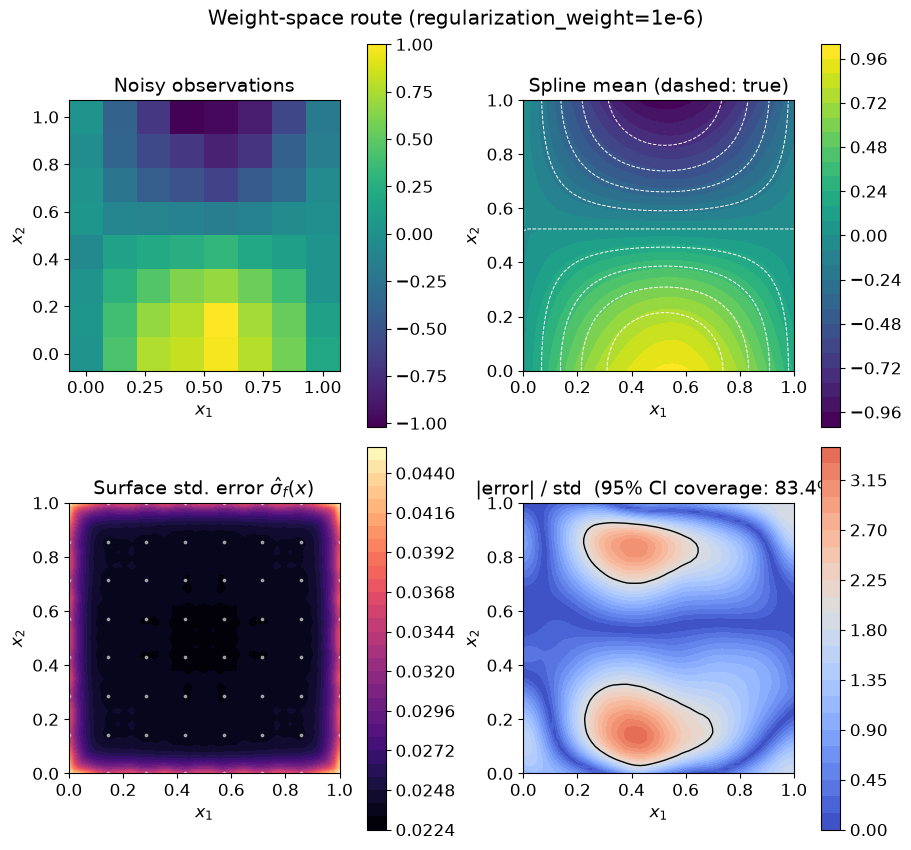

In [33]:
fig = plot_2d_maps(weight_space_uq, g, g, Z_noisy, f_true=f_true_2arg,
                    n_fine=61, title="Weight-space route (regularization_weight=1e-6)")
plt.show()


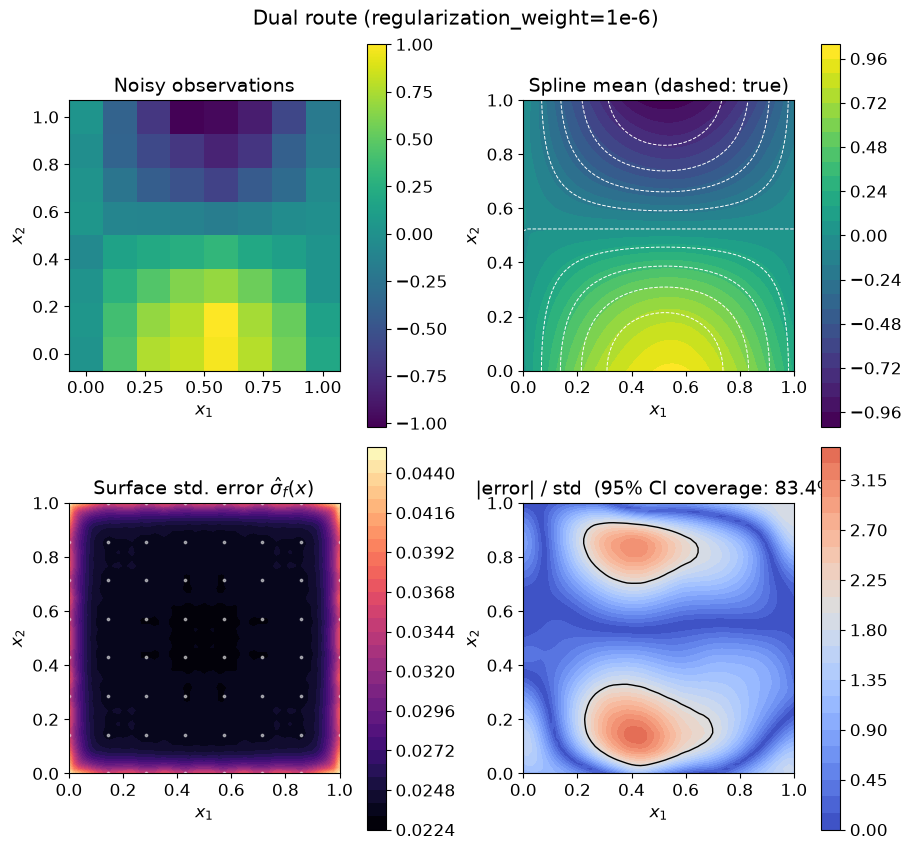

In [34]:
fig = plot_2d_maps(dual_uq, g, g, Z_noisy, f_true=f_true_2arg,
                    n_fine=61, title="Dual route (regularization_weight=1e-6)")
plt.show()


**Confirmed visually: the two maps are indistinguishable** -- as expected
from the `~2.5e-10` numerical agreement already established; any visible
difference here would itself have been a red flag worth investigating.

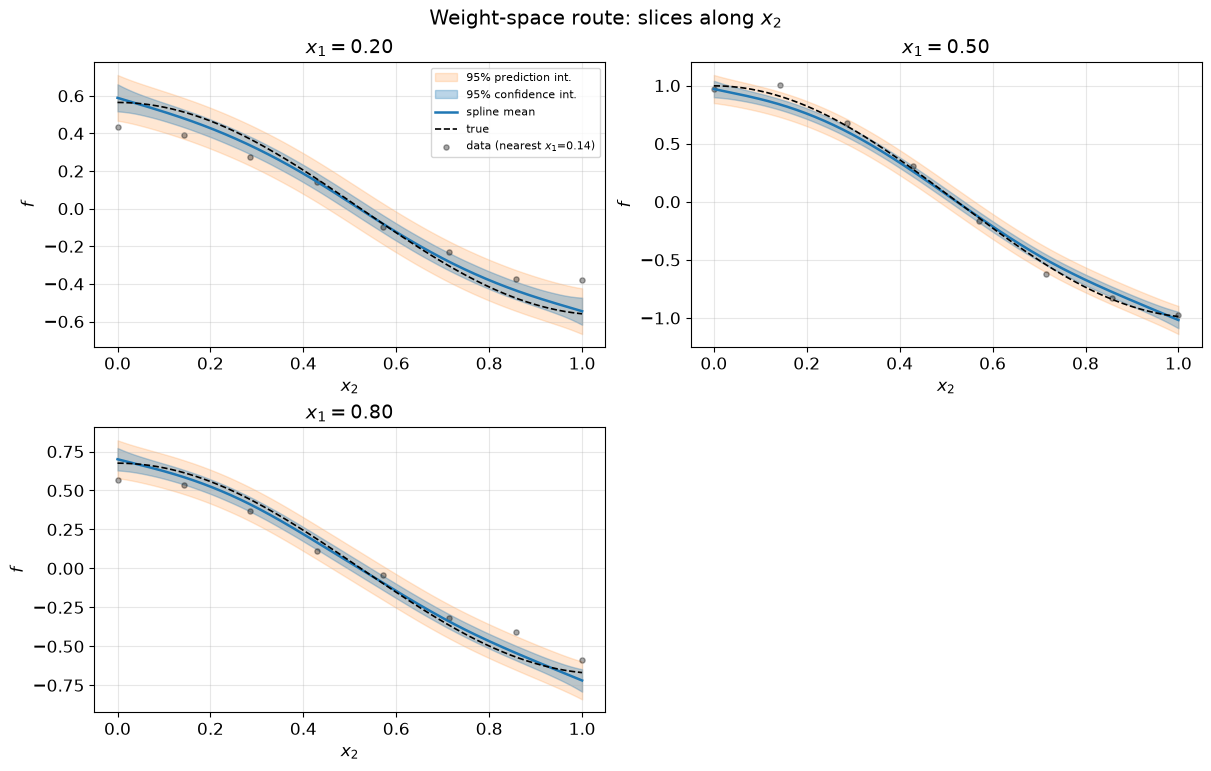

In [35]:
fig = plot_1d_slices(weight_space_uq, g, g, Z_noisy, axis=1, slice_values=[0.2, 0.5, 0.8],
                      f_true=f_true_2arg, title="Weight-space route: slices along $x_2$")
plt.show()


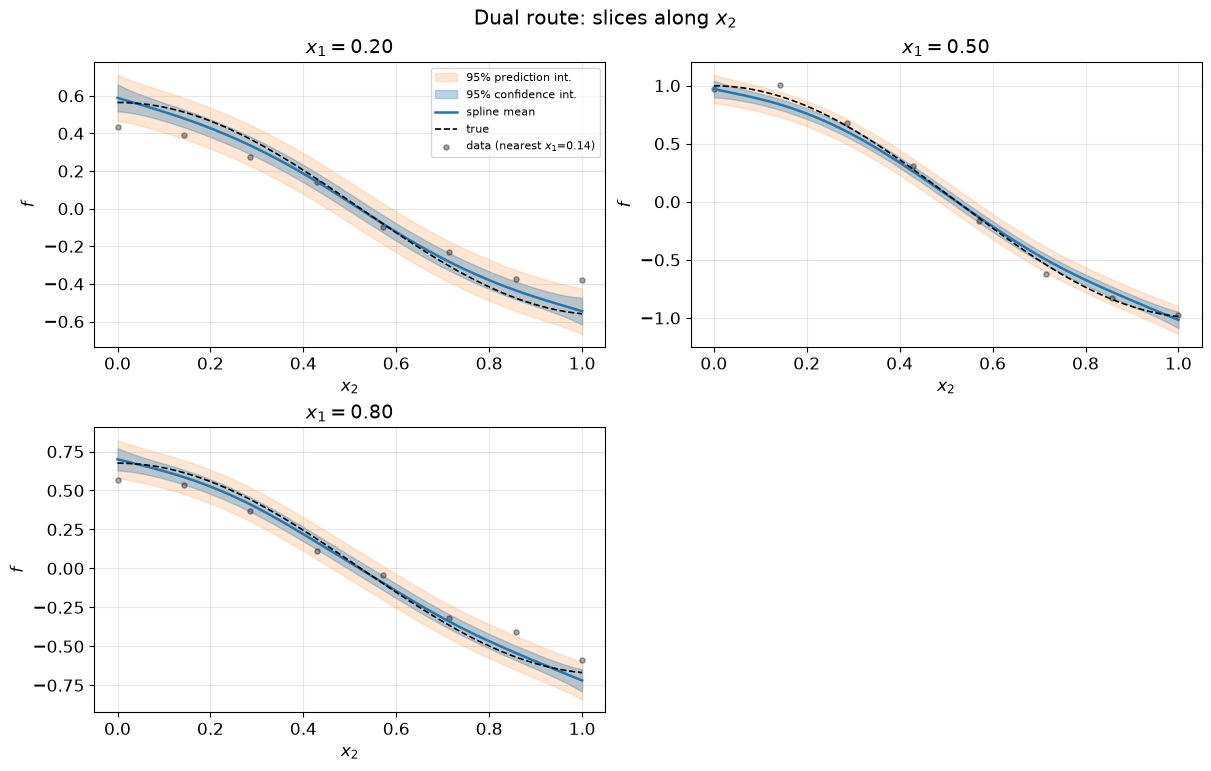

In [36]:
fig = plot_1d_slices(dual_uq, g, g, Z_noisy, axis=1, slice_values=[0.2, 0.5, 0.8],
                      f_true=f_true_2arg, title="Dual route: slices along $x_2$")
plt.show()


#### Direct overlay -- both routes' bands on the same panel

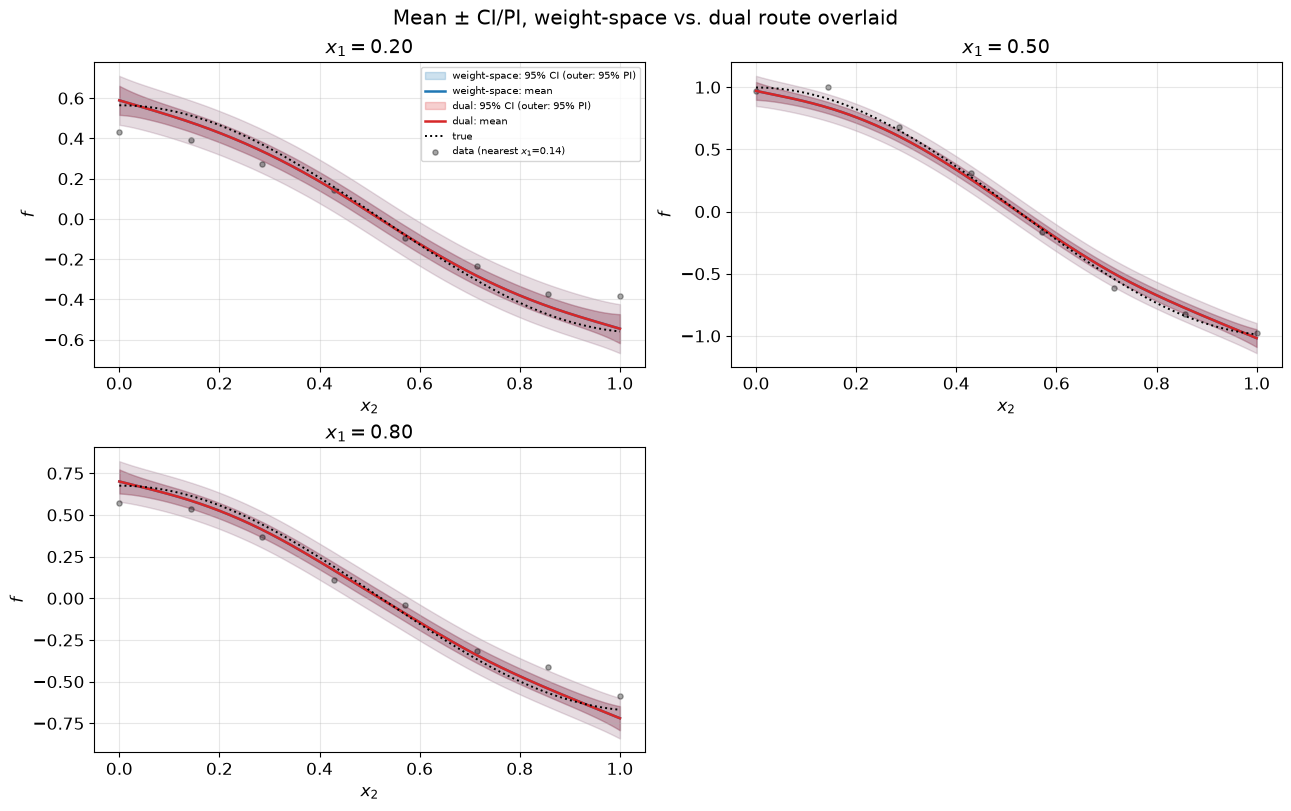

In [37]:
fig = plot_models_1d_slices([weight_space_uq, dual_uq], ["weight-space", "dual"],
                             g, g, Z_noisy, axis=1, slice_values=[0.2, 0.5, 0.8],
                             f_true=f_true_2arg,
                             title="Mean $\\pm$ CI/PI, weight-space vs. dual route overlaid")
plt.show()


## Conclusion (visual comparison)

Two structurally independent routes to RMTB's posterior mean and variance --
one solving an $m\times m$ system, the other an $n\times n$ system built
from a genuinely different object ($H^{-1}$, not $\mathrm{mtx}^{-1}$) -- now
visibly overlap exactly, not just agree in a table of numbers. This is the
clearest form this project's Phase F4 validation discipline has taken for
RMTB so far: not "two formulas that both call the same solve," but two
different linear systems, built two different ways, landing on the same
answer.

**In plain terms: the two recipes don't just taste the same in a blind
numeric test -- the cakes look identical side by side, slice by slice,
crumb for crumb. That's about as convincing as a picture can get that two
different ways of doing the math really are computing the same thing.**

Still open, unchanged by this section: the same picture *at RMTB's actual
default settings* (`regularization_weight=1e-14`), which needs the full
bordered-system derivation, not the regularization-boost workaround used
here.
